# AOL Introduction To Data Science

### Anggota Kelompok:

- Ann Abigail Halim [ID removed]
- Ivana Joyceline [ID removed]
- Nadya Angelie Lislie [ID removed]
- Vania Wyanet Tumbelaka [ID removed]

Kelas: LA06

# DATA PRE-PROCESSING (Part-1):

- Clean and Filter Data
- Extracting and Replacing Values

In [2]:
import numpy as np
import pandas as pd

from scipy import stats

import matplotlib.pylab as plt
from statsmodels.graphics.mosaicplot import mosaic


import seaborn as sns

### 1. Import Data

In [3]:
datas = pd.read_csv("StudentCompleteData.csv")
datas.head()

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,college undergraduate,standard,NaN,married,sometimes,yes,0.0,NaN,05-Oct,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,laki-laki,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,05-Oct,45,56,42
4,4,male,group C,college undergraduate,standard,none,married,sometimes,yes,0.0,school_bus,05-Oct,76,78,75


In [4]:
datas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30647 entries, 0 to 30646
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30647 non-null  int64  
 1   Gender               30647 non-null  object 
 2   EthnicGroup          28807 non-null  object 
 3   ParentEduc           28802 non-null  object 
 4   LunchType            30647 non-null  object 
 5   TestPrep             28817 non-null  object 
 6   ParentMaritalStatus  29457 non-null  object 
 7   PracticeSport        30016 non-null  object 
 8   IsFirstChild         29743 non-null  object 
 9   NrSiblings           29075 non-null  float64
 10  TransportMeans       27513 non-null  object 
 11  WklyStudyHours       29692 non-null  object 
 12  MathScore            30647 non-null  int64  
 13  ReadingScore         30647 non-null  int64  
 14  WritingScore         30647 non-null  int64  
dtypes: float64(1), int64(4), object(10)


### 2. Copy data pre-processing agar data asli tetap tersimpan

In [5]:
data = datas.copy()
data.head()

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,college undergraduate,standard,NaN,married,sometimes,yes,0.0,NaN,05-Oct,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,laki-laki,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,05-Oct,45,56,42
4,4,male,group C,college undergraduate,standard,none,married,sometimes,yes,0.0,school_bus,05-Oct,76,78,75


## Data Cleaning:

### 3. Remove Duplicate

In [6]:
data = data.drop_duplicates()

In [7]:
data.info()
# Ternyata jumlah datanya berkurang setelah remove duplicates
# Artinya terdapat data-data duplikat di file pre-processing sebelum di remove

<class 'pandas.core.frame.DataFrame'>
Int64Index: 30641 entries, 0 to 30646
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  object 
 2   EthnicGroup          28801 non-null  object 
 3   ParentEduc           28796 non-null  object 
 4   LunchType            30641 non-null  object 
 5   TestPrep             28811 non-null  object 
 6   ParentMaritalStatus  29451 non-null  object 
 7   PracticeSport        30010 non-null  object 
 8   IsFirstChild         29737 non-null  object 
 9   NrSiblings           29069 non-null  float64
 10  TransportMeans       27507 non-null  object 
 11  WklyStudyHours       29686 non-null  object 
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), object(10)


### 4. Cek konsistensi data

In [8]:
data['Gender'].value_counts()

female       15414
male         15209
perempuan       10
laki-laki        8
Name: Gender, dtype: int64

= Replace data yang tidak konsisten

In [9]:
# Data gender tidak konsisten, seharusnya female dan perempuan itu sama. Begitu pula dengan male dan laki-laki
data['Gender'] = data['Gender'].replace('perempuan', 'female')
data['Gender'] = data['Gender'].replace('laki-laki', 'male')

In [10]:
# Data Gender sudah konsisten
data['Gender'].value_counts()

female    15424
male      15217
Name: Gender, dtype: int64

In [11]:
data['EthnicGroup'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

group C    9212
group D    7503
group B    5826
group E    4041
group A    2219
Name: EthnicGroup, dtype: int64

In [12]:
data['ParentEduc'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

college undergraduate    6633
high school              5687
associate's degree       5550
high school dropout      5517
bachelor's degree        3386
master's degree          2023
Name: ParentEduc, dtype: int64

In [13]:
data['LunchType'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

standard        19905
free/reduced    10736
Name: LunchType, dtype: int64

In [14]:
data['TestPrep'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

none         18856
completed     9955
Name: TestPrep, dtype: int64

In [15]:
data['ParentMaritalStatus'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

married     16844
single       7097
divorced     4919
widowed       591
Name: ParentMaritalStatus, dtype: int64

In [16]:
data['PracticeSport'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

sometimes    15213
regularly    10793
never         4004
Name: PracticeSport, dtype: int64

In [17]:
data['IsFirstChild'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

yes    19082
no     10655
Name: IsFirstChild, dtype: int64

In [18]:
data['NrSiblings'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

1.0    8217
2.0    6790
3.0    6123
0.0    3085
4.0    2941
5.0    1320
6.0     302
7.0     291
Name: NrSiblings, dtype: int64

In [19]:
data['TransportMeans'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

school_bus    16145
private       11362
Name: TransportMeans, dtype: int64

In [20]:
data['WklyStudyHours'].value_counts()
# Terdapat kekeliruan data yaitu 05-Oct, sehingga perlu dilakukan replace data

05-Oct    16246
< 5        8238
> 10       5202
Name: WklyStudyHours, dtype: int64

In [21]:
data['WklyStudyHours'] = data['WklyStudyHours'].replace('05-Oct','5-10')

In [22]:
data['WklyStudyHours'].value_counts()
# Sudah konsisten = tidak perlu dilakukan replace data

5-10    16246
< 5      8238
> 10     5202
Name: WklyStudyHours, dtype: int64

### 5. Cek Missing Values dan Replace bila ada

In [23]:
data.info()
# Jumlah data Non-Null tiap Column tidak sama berarti ada missing values

<class 'pandas.core.frame.DataFrame'>
Int64Index: 30641 entries, 0 to 30646
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  object 
 2   EthnicGroup          28801 non-null  object 
 3   ParentEduc           28796 non-null  object 
 4   LunchType            30641 non-null  object 
 5   TestPrep             28811 non-null  object 
 6   ParentMaritalStatus  29451 non-null  object 
 7   PracticeSport        30010 non-null  object 
 8   IsFirstChild         29737 non-null  object 
 9   NrSiblings           29069 non-null  float64
 10  TransportMeans       27507 non-null  object 
 11  WklyStudyHours       29686 non-null  object 
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), object(10)


= Untuk data kualitatif, kita bisa replace data Nan dengan mode-nya

In [24]:
data['Gender'].isna().sum()
# Tidak ada Nan value

0

========================================================================================================================

In [25]:
data['EthnicGroup'].isna().sum()
# Ada Nan value

1840

In [26]:
data['EthnicGroup'].mode()

0    group C
Name: EthnicGroup, dtype: object

In [27]:
data['EthnicGroup'] = data['EthnicGroup'].fillna("group C")

In [28]:
data['EthnicGroup'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [29]:
data['ParentEduc'].isna().sum()
# Ada Nan value

1845

In [30]:
data['ParentEduc'].mode()

0    college undergraduate
Name: ParentEduc, dtype: object

In [31]:
data['ParentEduc'] = data['ParentEduc'].fillna("college undergraduate")

In [32]:
data['ParentEduc'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [33]:
data['LunchType'].isna().sum()
# Tidak ada Nan value

0

========================================================================================================================

In [34]:
data['TestPrep'].isna().sum()
# Ada Nan value

1830

In [35]:
data['TestPrep'].mode()

0    none
Name: TestPrep, dtype: object

In [36]:
data['TestPrep'] = data['TestPrep'].fillna("none")

In [37]:
data['TestPrep'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [38]:
data['ParentMaritalStatus'].isna().sum()
# Ada Nan value

1190

In [39]:
data['ParentMaritalStatus'].mode()

0    married
Name: ParentMaritalStatus, dtype: object

In [40]:
data['ParentMaritalStatus'] = data['ParentMaritalStatus'].fillna("married")

In [41]:
data['ParentMaritalStatus'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [42]:
data['PracticeSport'].isna().sum()
# Ada Nan value

631

In [43]:
data['PracticeSport'].mode()

0    sometimes
Name: PracticeSport, dtype: object

In [44]:
data['PracticeSport'] = data['PracticeSport'].fillna("sometimes")

In [45]:
data['PracticeSport'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [46]:
data['IsFirstChild'].isna().sum()
# Ada Nan value

904

In [47]:
data['IsFirstChild'].mode()

0    yes
Name: IsFirstChild, dtype: object

In [48]:
data['IsFirstChild'] = data['IsFirstChild'].fillna("yes")

In [49]:
data['IsFirstChild'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [50]:
data['TransportMeans'].isna().sum()
# Ada Nan value

3134

In [51]:
data['TransportMeans'].mode()

0    school_bus
Name: TransportMeans, dtype: object

In [52]:
data['TransportMeans'] = data['TransportMeans'].fillna("school_bus")

In [53]:
data['TransportMeans'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [54]:
data['WklyStudyHours'].isna().sum()
# Ada Nan value

955

In [55]:
data['WklyStudyHours'].mode()

0    5-10
Name: WklyStudyHours, dtype: object

In [56]:
data['WklyStudyHours'] = data['WklyStudyHours'].fillna("5-10")

In [57]:
data['WklyStudyHours'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

= Untuk data kuantitatif, kita periksa dulu apakah ada outlier di datanya atau tidak:
  - Bila ada, kita bisa replace data Nan dengan median-nya
  - Bila tidak ada, kita bisa replace data Nan dengan mean-nya

In [58]:
data['NrSiblings'].isna().sum()
# Ada Nan value

1572

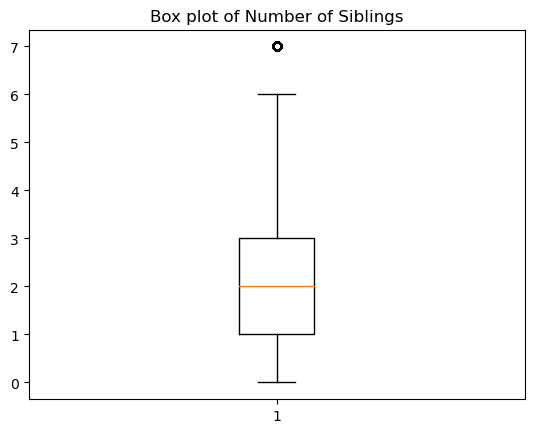

In [59]:
siblings = data['NrSiblings'].dropna()
fig, box1 = plt.subplots()
box1.set_title("Box plot of Number of Siblings")
plt.boxplot(siblings)
plt.show()

In [60]:
# Dari graph di atas, terdapat outlier karena ada titik di luar box-plot. Jadi, kita akan isi data nan dengan nilai median-nya
siblings.median()

2.0

In [61]:
data['NrSiblings'] = data['NrSiblings'].fillna(2)

In [62]:
data['NrSiblings'].isna().sum()
# Nan value sudah berhasil diisi dengan mode

0

========================================================================================================================

In [63]:
data['MathScore'].isna().sum()
# Tidak ada Nan value

0

========================================================================================================================

In [64]:
data['ReadingScore'].isna().sum()
# Tidak ada Nan value

0

========================================================================================================================

In [65]:
data['WritingScore'].isna().sum()
# Tidak ada Nan value

0

========================================================================================================================

= Periksa kembali info datanya untuk memastikan Nan-values sudah terisi

In [66]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 30641 entries, 0 to 30646
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  object 
 2   EthnicGroup          30641 non-null  object 
 3   ParentEduc           30641 non-null  object 
 4   LunchType            30641 non-null  object 
 5   TestPrep             30641 non-null  object 
 6   ParentMaritalStatus  30641 non-null  object 
 7   PracticeSport        30641 non-null  object 
 8   IsFirstChild         30641 non-null  object 
 9   NrSiblings           30641 non-null  float64
 10  TransportMeans       30641 non-null  object 
 11  WklyStudyHours       30641 non-null  object 
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), object(10)


### Data cleaning sudah selesai

# DATA PRE-PROCESSING (Part-2):

- Convert Data From One Format to Another
- Split, Merge, and Extract Columns

In [67]:
# data csvnya memiliki satu column index yang terbaca menjaadi unknown,
# ada baiknya dihilangkan.
data.drop("Unnamed: 0", axis=1, inplace=True)
data.head()

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,female,group C,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,female,group C,college undergraduate,standard,none,married,sometimes,yes,0.0,school_bus,5-10,69,90,88
2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,school_bus,5-10,45,56,42
4,male,group C,college undergraduate,standard,none,married,sometimes,yes,0.0,school_bus,5-10,76,78,75


In [68]:
data.to_excel('DataInExcel.xlsx', index=False)

In [69]:
excel = pd.read_excel('DataInExcel.xlsx')
excel.head()

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,female,group C,bachelor's degree,standard,none,married,regularly,yes,3,school_bus,< 5,71,71,74
1,female,group C,college undergraduate,standard,none,married,sometimes,yes,0,school_bus,5-10,69,90,88
2,female,group B,master's degree,standard,none,single,sometimes,yes,4,school_bus,< 5,87,93,91
3,male,group A,associate's degree,free/reduced,none,married,never,no,1,school_bus,5-10,45,56,42
4,male,group C,college undergraduate,standard,none,married,sometimes,yes,0,school_bus,5-10,76,78,75


In [70]:
data.to_json('DataInJson.json')

In [71]:
json = pd.read_json('DataInJson.json')
json.head()

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,female,group C,bachelor's degree,standard,none,married,regularly,yes,3,school_bus,< 5,71,71,74
1,female,group C,college undergraduate,standard,none,married,sometimes,yes,0,school_bus,5-10,69,90,88
2,female,group B,master's degree,standard,none,single,sometimes,yes,4,school_bus,< 5,87,93,91
3,male,group A,associate's degree,free/reduced,none,married,never,no,1,school_bus,5-10,45,56,42
4,male,group C,college undergraduate,standard,none,married,sometimes,yes,0,school_bus,5-10,76,78,75


In [72]:
#split = misalnya kita tidak mau memisahkan 
#kata group dari nama groupmnya di ethnic group
data['EthnicGroup'].str.split(" ", expand=True)

,0,1
0,group,C
1,group,C
2,group,B
3,group,A
4,group,C
...,...,...
30642,group,D
30643,group,E
30644,group,C
30645,group,D


In [73]:
#merge misalnya mau menggabungkan column Gender dengan EthnicGroup
merge = data['Gender']+ " " + data['EthnicGroup']
merge

0        female group C
1        female group C
2        female group B
3          male group A
4          male group C
              ...      
30642    female group D
30643      male group E
30644    female group C
30645    female group D
30646      male group B
Length: 30641, dtype: object

In [74]:
Datas = {'Gender' : data['Gender'],
         'PracticeSport' : data['PracticeSport'],
         'TransportMeans' : data['TransportMeans']}
datas = pd.DataFrame(Datas)
datas.head()

,Gender,PracticeSport,TransportMeans
0,female,regularly,school_bus
1,female,sometimes,school_bus
2,female,sometimes,school_bus
3,male,never,school_bus
4,male,sometimes,school_bus


In [75]:
#extract misalnya hanya ambil column PracticeSport
datas.iloc[0::, 1:2]

,PracticeSport
0,regularly
1,sometimes
2,sometimes
3,never
4,sometimes
...,...
30642,sometimes
30643,regularly
30644,sometimes
30645,regularly


In [76]:
#misalnya mau extract sekaligus mencari data spesifik untuk di extract
data[data['PracticeSport'].isin(['never'])]

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,school_bus,5-10,45,56,42
7,female,group B,college undergraduate,standard,completed,widowed,never,no,1.0,private,5-10,85,93,89
20,female,group C,associate's degree,free/reduced,none,married,never,yes,3.0,private,< 5,50,56,58
23,male,group D,college undergraduate,standard,none,married,never,yes,5.0,school_bus,5-10,42,53,51
24,female,group C,high school dropout,standard,none,divorced,never,no,3.0,school_bus,5-10,66,71,71
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30618,female,group B,high school,standard,none,married,never,no,3.0,school_bus,< 5,61,87,78
30622,male,group C,high school,standard,none,married,never,no,3.0,private,< 5,71,68,63
30633,female,group A,high school,standard,completed,married,never,no,2.0,school_bus,> 10,58,77,82
30639,female,group C,master's degree,standard,completed,married,never,no,2.0,school_bus,5-10,84,99,99


# DATA EXPLORATION (Part-1):

- Inspect the Data and Its Properties
- Compute Descriptive Statistics

In [77]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 30641 entries, 0 to 30646
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               30641 non-null  object 
 1   EthnicGroup          30641 non-null  object 
 2   ParentEduc           30641 non-null  object 
 3   LunchType            30641 non-null  object 
 4   TestPrep             30641 non-null  object 
 5   ParentMaritalStatus  30641 non-null  object 
 6   PracticeSport        30641 non-null  object 
 7   IsFirstChild         30641 non-null  object 
 8   NrSiblings           30641 non-null  float64
 9   TransportMeans       30641 non-null  object 
 10  WklyStudyHours       30641 non-null  object 
 11  MathScore            30641 non-null  int64  
 12  ReadingScore         30641 non-null  int64  
 13  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(3), object(10)
memory usage: 4.5+ MB


## 1. ukuran pemusatan data

In [78]:
data.describe()

,NrSiblings,MathScore,ReadingScore,WritingScore
count,30641.000000,30641.000000,30641.000000,30641.000000
mean,2.138409,66.558402,69.377533,68.418622
std,1.420707,15.361616,14.758952,15.443525
min,0.000000,0.000000,10.000000,4.000000
25%,1.000000,56.000000,59.000000,58.000000
50%,2.000000,67.000000,70.000000,69.000000
75%,3.000000,78.000000,80.000000,79.000000
max,7.000000,100.000000,100.000000,100.000000


Interpretasi data:
- Untuk menyajikan statistik deskriptif dari suatu DataFrame / DataSet
- Digunakan untuk memberikan ringkasan cepat mengenai kecenderungan pusat, dispersi, dan bentuk distribusi dari suatu DataFrame / DataSet
- Menampilkan tabel ringkasan yang mencakup count (jumlah data), mean (rata-rata), standar deviasi, minimum, kuartil pertama (25%), median (50%), kuartil ketiga (75%), dan maksimum untuk setiap kolom dalam DataFrame / DataSet

In [79]:
data['MathScore'].mean()

66.5584021409223

interpretasi data
- untuk menyajikan mean (rata-rata) nilai Mathscore dari DataSet yang tersedia

In [80]:
data['ReadingScore'].mean()

69.37753337032082

interpretasi data
- untuk menyajikan mean (rata-rata) nilai ReadingScore dari DataSet yang tersedia

In [81]:
data['WritingScore'].mean()

68.41862210763357

interpretasi data
- untuk menyajikan mean (rata-rata) nilai WritingScore dari DataSet yang tersedia

In [82]:
data['MathScore'].median()

67.0

interpretasi data
- untuk menyajikan nilai median (nilai tengah) MathScore dari DataSet yang tersedia

In [83]:
data['ReadingScore'].median()

70.0

interpretasi data
- untuk menyajikan nilai median (nilai tengah) ReadingScore dari DataSet yang tersedia

In [84]:
data['WritingScore'].median()

69.0

interpretasi data
- untuk menyajikan nilai median (nilai tengah) WritingScore dari DataSet yang tersedia

In [85]:
data['MathScore'].max()

100

interpretasi data
- untuk menyajikan maksimum nilai MathScore dari DataSet yang tersedia

In [86]:
data['ReadingScore'].max()

100

interpretasi data
- untuk menyajikan maksimum nilai ReadingScore dari DataSet yang tersedia

In [87]:
data['WritingScore'].max()

100

interpretasi data
- untuk menyajikan maksimum nilai WritingScore dari DataSet yang tersedia

In [88]:
data['MathScore'].min()

0

interpretasi data
- untuk menyajikan minimum nilai MathScore dari DataSet yang tersedia

In [89]:
data['ReadingScore'].min()

10

interpretasi data
- untuk menyajikan minimum nilai ReadingScore dari DataSet yang tersedia

In [90]:
data['WritingScore'].min()

4

interpretasi data
- untuk menyajikan minimum nilai WritingScore dari DataSet yang tersedia

In [91]:
data['MathScore'].quantile(0.25)

56.0

interpretasi data
- untuk menyajikan kuartil bawah nilai MathScore dari DataSet yang tersedia

In [92]:
data['ReadingScore'].quantile(0.25)

59.0

interpretasi data
- untuk menyajikan kuartil bawah nilai ReadingScore dari DataSet yang tersedia

In [93]:
data['WritingScore'].quantile(0.25)

58.0

interpretasi data
- untuk menyajikan kuartil bawah nilai WritingScore dari DataSet yang tersedia

In [94]:
data['MathScore'].quantile(0.75)

78.0

interpretasi data
- untuk menyajikan kuartil atas nilai MathScore dari DataSet yang tersedia

In [95]:
data['ReadingScore'].quantile(0.75)

80.0

interpretasi data
- untuk menyajikan kuartil atas nilai ReadingScore dari DataSet yang tersedia

In [96]:
data['WritingScore'].quantile(0.75)

79.0

interpretasi data
- untuk menyajikan kuartil atas nilai WritingScore dari DataSet yang tersedia

## 2. Ukuran Penyebaran Data

In [97]:
stats.describe(data['MathScore'])

DescribeResult(nobs=30641, minmax=(0, 100), mean=66.5584021409223, variance=235.97923431360377, skewness=-0.16285365843829858, kurtosis=-0.2399971877846676)

Interpretasi data
- digunakan untuk menghasilkan deskripsi statistik ringkas dari Data numerik MathScore.
- menyediakan berbagai statistik seperti rata-rata, standar deviasi, kurtosis, skewness, 
  dan beberapa informasi statistik lainnya

In [98]:
stats.describe(data['ReadingScore'])

DescribeResult(nobs=30641, minmax=(10, 100), mean=69.37753337032082, variance=217.82665450300678, skewness=-0.1812789434248369, kurtosis=-0.2774044033276222)

Interpretasi data
- digunakan untuk menghasilkan deskripsi statistik ringkas dari Data numerik ReadingScore.
- menyediakan berbagai statistik seperti rata-rata, standar deviasi, kurtosis, skewness, 
  dan beberapa informasi statistik lainnya

In [99]:
stats.describe(data['WritingScore'])

DescribeResult(nobs=30641, minmax=(4, 100), mean=68.41862210763357, variance=238.50245868881805, skewness=-0.1598221418289711, kurtosis=-0.30040619545250635)

Interpretasi data
- digunakan untuk menghasilkan deskripsi statistik ringkas dari Data numerik WritingScore.
- menyediakan berbagai statistik seperti rata-rata, standar deviasi, kurtosis, skewness, 
  dan beberapa informasi statistik lainnya

In [100]:
data['MathScore'].var()

235.9792343136052

Interpretasi data
- digunakan untuk menghitung varians dari suatu DataSet numerik MathScore
- Varians merupakan ukuran sebaran data yang mengukur sejauh mana setiap nilai dalam DataSet berbeda dari rata-rata (mean) dataset tersebut.

In [101]:
data['ReadingScore'].var()

217.82665450300735

Interpretasi data
- digunakan untuk menghitung varians dari suatu DataSet numerik ReadingScore
- Varians merupakan ukuran sebaran data yang mengukur sejauh mana setiap nilai dalam DataSet berbeda dari rata-rata (mean) dataset tersebut.

In [102]:
data['WritingScore'].var()

238.5024586888112

Interpretasi data
- digunakan untuk menghitung varians dari suatu DataSet numerik WritingScore
- Varians merupakan ukuran sebaran data yang mengukur sejauh mana setiap nilai dalam DataSet berbeda dari rata-rata (mean) dataset tersebut.

In [103]:
stats.iqr(data['MathScore'])

22.0

Interpretasi data
- digunakan untuk menghitung Rentang Interkuartil (Interquartile Range/IQR) dari DataSet MathScore.
- IQR adalah perbedaan antara kuartil ketiga (Q3) dan kuartil pertama (Q1). 
- IQR memberikan informasi tentang sebaran nilai-nilai dalam bagian tengah DataSet.

In [104]:
stats.iqr(data['ReadingScore'])

21.0

Interpretasi data
- digunakan untuk menghitung Rentang Interkuartil (Interquartile Range/IQR) dari DataSet ReadingScore.
- IQR adalah perbedaan antara kuartil ketiga (Q3) dan kuartil pertama (Q1). 
- IQR memberikan informasi tentang sebaran nilai-nilai dalam bagian tengah DataSet.

In [105]:
stats.iqr(data['WritingScore'])

21.0

Interpretasi data
- digunakan untuk menghitung Rentang Interkuartil (Interquartile Range/IQR) dari DataSet WritingScore.
- IQR adalah perbedaan antara kuartil ketiga (Q3) dan kuartil pertama (Q1). 
- IQR memberikan informasi tentang sebaran nilai-nilai dalam bagian tengah DataSet.

In [106]:
data['MathScore'].std()

15.3616156153448

Interpretasi data
- digunakan untuk menghitung deviasi standar dari suatu DataSet numerik MathScore.
- digunakan juga untuk mengukur seberapa jauh setiap nilai dalam dataset berbeda dari rata-rata (mean) dataset tersebut.

In [107]:
data['ReadingScore'].std()

14.758951673577881

Interpretasi data
- digunakan untuk menghitung deviasi standar dari suatu DataSet numerik ReadingScore.
- digunakan juga untuk mengukur seberapa jauh setiap nilai dalam dataset berbeda dari rata-rata (mean) dataset tersebut.

In [108]:
data['WritingScore'].std()

15.443524814264753

Interpretasi data
- digunakan untuk menghitung deviasi standar dari suatu DataSet numerik WritingScore.
- digunakan juga untuk mengukur seberapa jauh setiap nilai dalam dataset berbeda dari rata-rata (mean) dataset tersebut.

# DATA EXPLORATION (Part-2):

- Test Significant Variables (Correlation)
- Gain Some Data Visualization Through Simple Formating of Charts

In [109]:
score = {'MathScore' : data['MathScore'],
         'ReadingScore' : data['ReadingScore'],
         'WritingScore' : data['WritingScore']}
DataScore = pd.DataFrame(score)
DataScore.head()

,MathScore,ReadingScore,WritingScore
0,71,71,74
1,69,90,88
2,87,93,91
3,45,56,42
4,76,78,75


In [110]:
a = DataScore.corr()
a

,MathScore,ReadingScore,WritingScore
MathScore,1.000000,0.817825,0.807118
ReadingScore,0.817825,1.000000,0.952584
WritingScore,0.807118,0.952584,1.000000


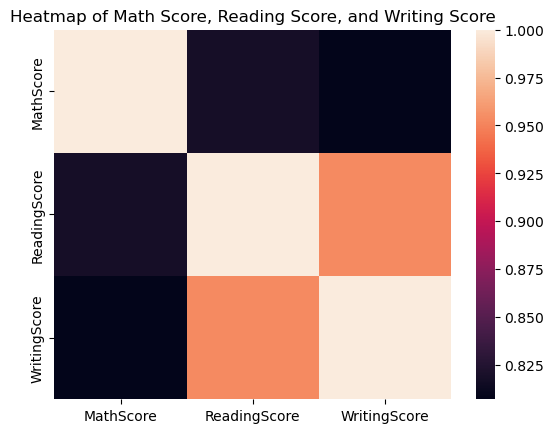

In [111]:
sns.heatmap(a)
plt.title("Heatmap of Math Score, Reading Score, and Writing Score")
plt.show()

Interpretasi Data:
- Ketiga nilai memiliki korelasi positif yang kuat antara satu dengan yang lainnya. Artinya, saat nilai siswa naik di salah satu mata pelajaran, terlihat bahwa nilai di mata pelajaran lain juga naik. Begitu pula saat salah satu nilai turun, nilai lain juga menurun di mayoritas kasus.
- Semakin gelap warna kotaknya, semakin lemah korelasi antara kedua variabel.
- Korelasi yang terkuat berdasarkan data dan heatmap di atas adalah antara Reading Score dengan Writing Score. Nilai korelasinya bahkan mendekati 1, yaitu 0.952584.
- Berdasarkan heatmap tersebut juga terlihat bahwa korelasi antara Reading Score dengan Math score hanya sedikit lebih kuat dibandingkan korelasi antara Writing Score dan Math Score.

In [112]:
nrsibToscore = {'MathScore' : data['MathScore'],
                'ReadingScore' : data['ReadingScore'],
                'WritingScore' : data['WritingScore'],
                'NumbersOfSiblings' : data['NrSiblings']}
DataCompare = pd.DataFrame(nrsibToscore)
b = DataCompare.corr()
b

,MathScore,ReadingScore,WritingScore,NumbersOfSiblings
MathScore,1.000000,0.817825,0.807118,-0.001084
ReadingScore,0.817825,1.000000,0.952584,-0.000796
WritingScore,0.807118,0.952584,1.000000,-0.002375
NumbersOfSiblings,-0.001084,-0.000796,-0.002375,1.000000


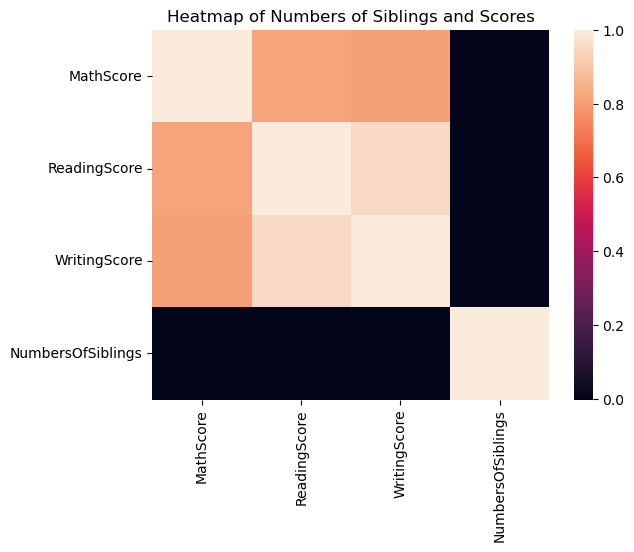

In [113]:
sns.heatmap(b)
plt.title("Heatmap of Numbers of Siblings and Scores")
plt.show()

Interpretasi Data:
- Melanjutkan interpretasi yang sudah dilakukan untuk heatmap sebelumnya, heatmat ini menambah 1 variabel, yaitu NumbersOfSiblings.
- Terlihat bahwa korelasi antara NumbersOfSibings dengan semua jenis nilai mendekati nol dari scale(karena warnanya sangat gelap). Artinya, NumbersOfSiblings hampir tidak memiliki hubungan atau korelasi dengan nilai. Kenaikan jumlah saudara misalnya tidak akan begitu mempengaruhi kenaikan atau penurunan nilai.
- Bila kita perhatikan tabel korelasi di atas heatmap ini terlihat pula nilai korelasinya negatif sangat lemah karena tidak mendekati -1 sama sekali.

### A. Hubungan Nilai dengan Gender:

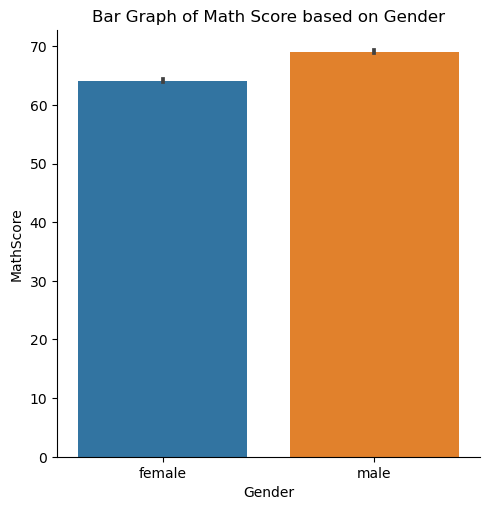

In [114]:
sns.catplot(x="Gender", y="MathScore", kind='bar', data=data)
plt.title("Bar Graph of Math Score based on Gender")
plt.show()

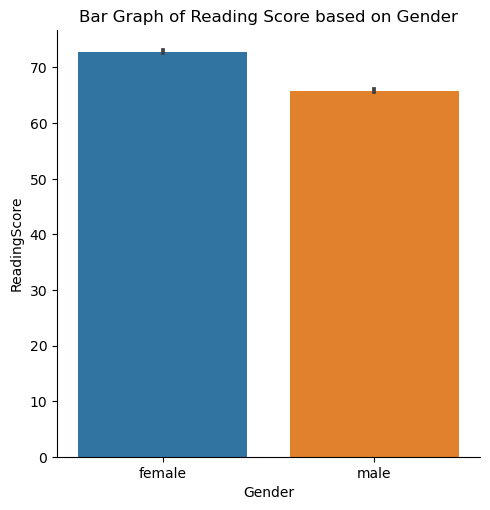

In [115]:
sns.catplot(x="Gender", y="ReadingScore", kind='bar', data=data)
plt.title("Bar Graph of Reading Score based on Gender")
plt.show()

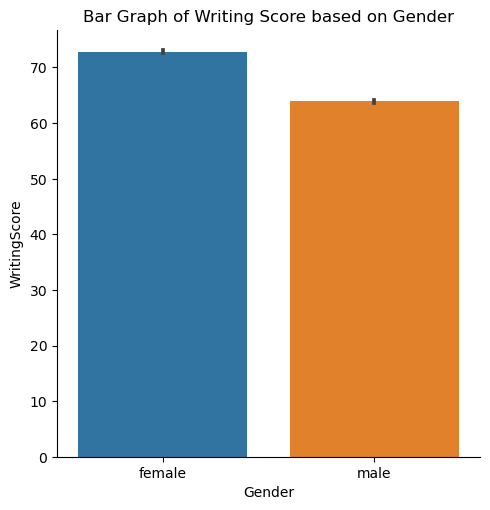

In [116]:
sns.catplot(x="Gender", y="WritingScore", kind='bar', data=data)
plt.title("Bar Graph of Writing Score based on Gender")
plt.show()

(Interpretasi di bawah sudah mencangkup 3 bar graph di atas)

Interpretasi Data:
- Bar graph pertama menampilkan bahwa secara general, laki-laki memiliki nilai matematika yang lebih tinggi dibandingkan milik perempuan. Ini mengindikasikan bahwa berdasarkan dataset ini, murid laki-laki lebih menguasai materi matematika yang diujikan.
- Bar graph kedua dan ketiga menampilkan bahwa secara general, perempuan memiliki nilai reading dan writing yang lebih tinggi dibandingkan milik laki-laki. Ini mengindikasikan bahwa berdasarkan dataset ini, murid perempuan lebih menguasai materi reading dan writing yang diujikan.

### B.Hubungan Nilai dengan Ethnic Group

In [117]:
ethnic = data.sort_values(by='EthnicGroup', ascending=True)

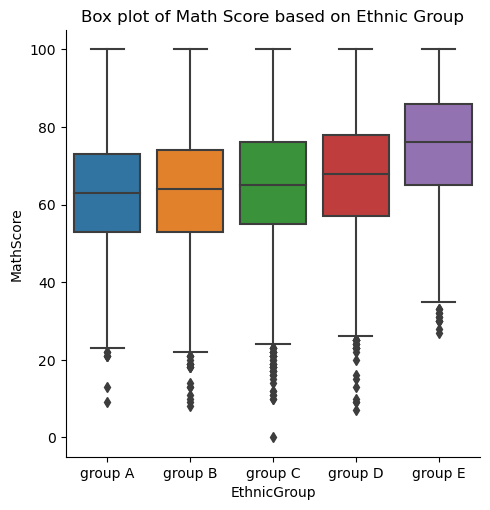

In [118]:
sns.catplot(x="EthnicGroup", y="MathScore", kind='box', data=ethnic)
plt.title("Box plot of Math Score based on Ethnic Group")
plt.show()

Interpretasi Data:
- Box plot di atas menampilkan bahwa nilai metematika tertinggi dari setiap etnis sama, yaitu 100.
- Kemudian, nilai matematika terendah dari semua siswa dimiliki oleh etnis group C.
- Urutan median nilai metematika dari yang tertinggi adalah group E, group D, group C, group B, dan group A.
- Group C memiliki range nilai matematika yang paling luas, sedangkan group E memiliki range nilai yang paling kecil.
- Semua group memiliki nilai outlier yang jauh berbeda dari daerah quartil-quartil group tersebut.

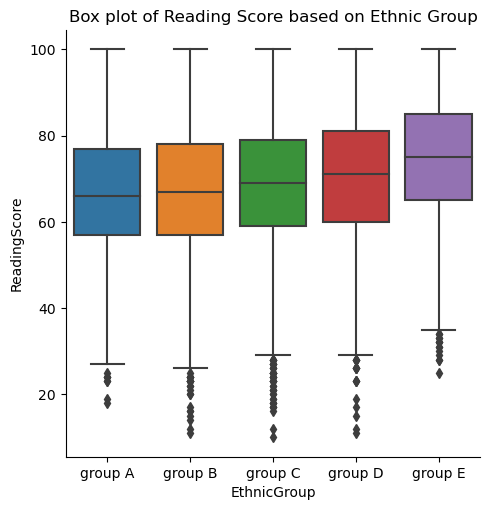

In [119]:
sns.catplot(x="EthnicGroup", y="ReadingScore", kind='box', data=ethnic)
plt.title("Box plot of Reading Score based on Ethnic Group")
plt.show()

Interpretasi Data:
- Box plot di atas menampilkan bahwa nilai reading tertinggi dari setiap etnis sama, yaitu 100.
- Kemudian, nilai reading terendah dari semua siswa dimiliki oleh etnis group C.
- Urutan median nilai reading dari yang tertinggi adalah group E, group D, group C, group B, dan group A.
- Group C memiliki range nilai reading yang paling luas, sedangkan group E memiliki range nilai yang paling kecil.
- Semua group memiliki nilai outlier yang jauh berbeda dari daerah quartil-quartil group tersebut.

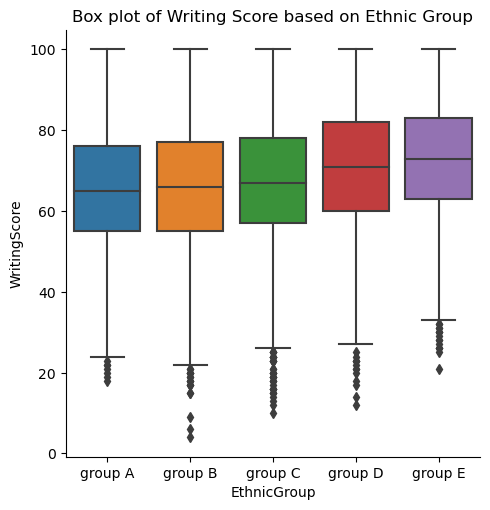

In [120]:
sns.catplot(x="EthnicGroup", y="WritingScore", kind='box', data=ethnic)
plt.title("Box plot of Writing Score based on Ethnic Group")
plt.show()

Interpretasi Data:
- Box plot di atas menampilkan bahwa nilai writing tertinggi dari setiap etnis sama, yaitu 100.
- Kemudian, nilai writing terendah dari semua siswa dimiliki oleh etnis group B.
- Urutan median nilai writing dari yang tertinggi adalah group E, group D, group C, group B, dan group A.
- Group B memiliki range nilai writing yang paling luas, sedangkan group E memiliki range nilai yang paling kecil.
- Semua group memiliki nilai outlier yang jauh berbeda dari daerah quartil-quartil group tersebut.

### C.Hubungan Nilai dengan Parent Education

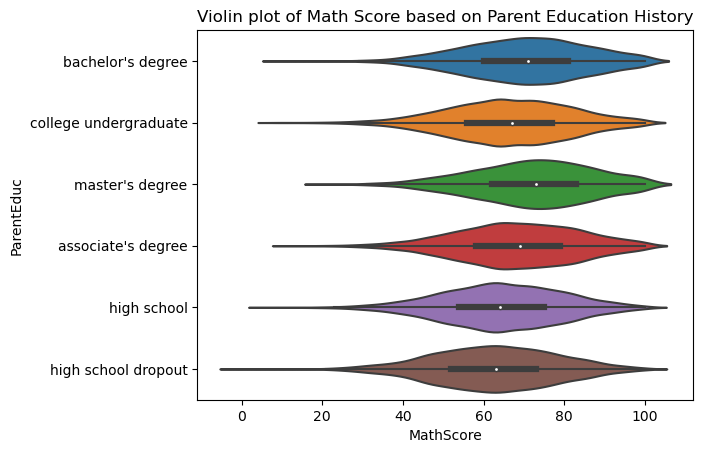

In [121]:
sns.violinplot(x="MathScore", y="ParentEduc", data=data)
plt.title("Violin plot of Math Score based on Parent Education History")
plt.show()

Interpretasi Data:
- Violin plot di atas menampilkan bahwa anak dari orang tua yang memiliki master's degree memiliki median nilai matematika yang paling tinggi dibandingkan anak dari orang tua lulusan lainnya.
- Nilai minimum anak dari orang tua yang memiliki master's degree juga terlihat paling tinggi di bandingkan yang lain, yaitu di dekat 20.
- Kemudian, median nilai matematika terendah dimiliki oleh anak dari orang tua high school dropout.

Distribusi nilai:
- Bentuk distribusi dari setiap violin plot sangat kurus di area nilai matematika yang sekitar 40 ke bawah menunjukkan bahwa semakin rendah nilainya, semakin jarang ada anak yang memiliki nilai tersebut mau lulusan apapun orang tuanya.
- Distribusi nilai matematika anak dari orang tua dengan bachelor's degree berkonsentrasi di sekitar median dan kuartil atas.
- Distribusi nilai matematika anak dari orang tua college undergraduate berkonsentrasi di sekitar nilai di bawah median dan nilai yang mendekati kuartil atas.
- Distribusi nilai matematika anak dari orang tua dengan master's degree berkonsentrasi di sekitar median.
- Distribusi nilai matematika anak dari orang tua dengan associate's degree berkonsentrasi di sekitar nilai di bawah median.
- Distribusi nilai matematika anak dari orang tua lulusan high school berkonsentrasi di sekitar median.
- Distribusi nilai matematika anak dari orang tua high school dropout berkonsentrasi di sekitar median.

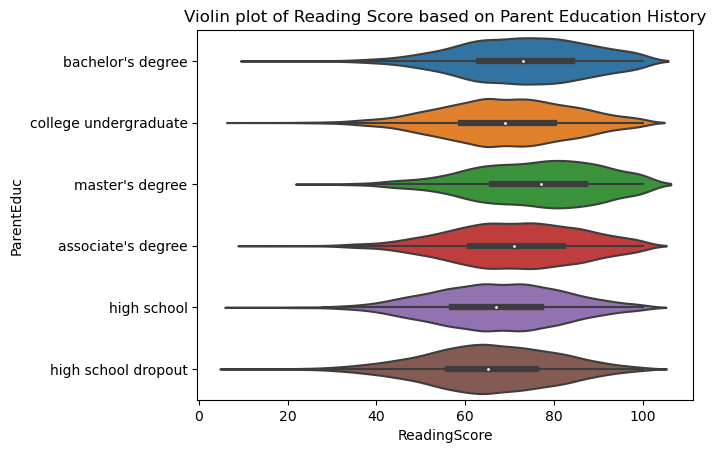

In [122]:
sns.violinplot(x="ReadingScore", y="ParentEduc", data=data)
plt.title("Violin plot of Reading Score based on Parent Education History")
plt.show()

Interpretasi Data:
- Violin plot di atas menampilkan bahwa anak dari orang tua yang memiliki master's degree memiliki median nilai reading yang paling tinggi dibandingkan anak dari orang tua lulusan lainnya.
- Nilai minimum anak dari orang tua yang memiliki master's degree juga terlihat paling tinggi di bandingkan yang lain, yaitu di atas 20.
- Kemudian, median nilai reading terendah dimiliki oleh anak dari orang tua high school dropout.

Distribusi nilai:
- Bentuk distribusi dari setiap violin plot sangat kurus di area nilai reading yang sekitar 30 ke bawah menunjukkan bahwa semakin rendah nilainya, semakin jarang ada anak yang memiliki nilai tersebut mau lulusan apapun orang tuanya.
- Distribusi nilai reading anak dari orang tua dengan bachelor's degree berkonsentrasi di sekitar area antara quartil atas dan bawah.
- Distribusi nilai reading anak dari orang tua college undergraduate berkonsentrasi di sekitar nilai di bawah dan di atas median.
- Distribusi nilai reading anak dari orang tua dengan master's degree berkonsentrasi di sekitar bagian atas median.
- Distribusi nilai reading anak dari orang tua dengan associate's degree berkonsentrasi di sekitar nilai di bawah dan atas median.
- Distribusi nilai reading anak dari orang tua lulusan high school berkonsentrasi di area sebelum kuartil atas.
- Distribusi nilai reading anak dari orang tua high school dropout berkonsentrasi di area sebelum median.

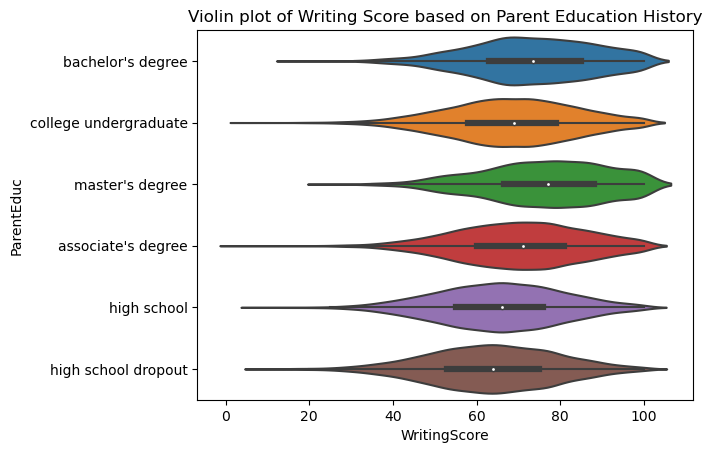

In [123]:
sns.violinplot(x="WritingScore", y="ParentEduc", data=data)
plt.title("Violin plot of Writing Score based on Parent Education History")
plt.show()

Interpretasi Data:
- Violin plot di atas menampilkan bahwa anak dari orang tua yang memiliki master's degree memiliki median nilai writing yang paling tinggi dibandingkan anak dari orang tua lulusan lainnya.
- Nilai minimum anak dari orang tua yang memiliki master's degree juga terlihat paling tinggi di bandingkan yang lain, yaitu di sekitar 20.
- Kemudian, median nilai writing terendah dimiliki oleh anak dari orang tua high school dropout.

Distribusi nilai:
- Bentuk distribusi dari setiap violin plot sangat kurus di area nilai writing yang sekitar 30 ke bawah menunjukkan bahwa semakin rendah nilainya, semakin jarang ada anak yang memiliki nilai tersebut mau lulusan apapun orang tuanya.
- Distribusi nilai writing anak dari orang tua dengan bachelor's degree berkonsentrasi di sekitar area di atas kuartil bawah.
- Distribusi nilai writing anak dari orang tua college undergraduate berkonsentrasi di sekitar nilai di bawah dan di atas median.
- Distribusi nilai writing anak dari orang tua dengan master's degree berkonsentrasi di area antara kuartil bawah dengan kuartil atas.
- Distribusi nilai writing anak dari orang tua dengan associate's degree berkonsentrasi disekitar bawah kuartil atas.
- Distribusi nilai writing anak dari orang tua lulusan high school berkonsentrasi di median.
- Distribusi nilai writing anak dari orang tua high school dropout berkonsentrasi di median.

### D. Hubungan Nilai dengan Parent Education yang berasal dari Ethnic Group yang berbeda

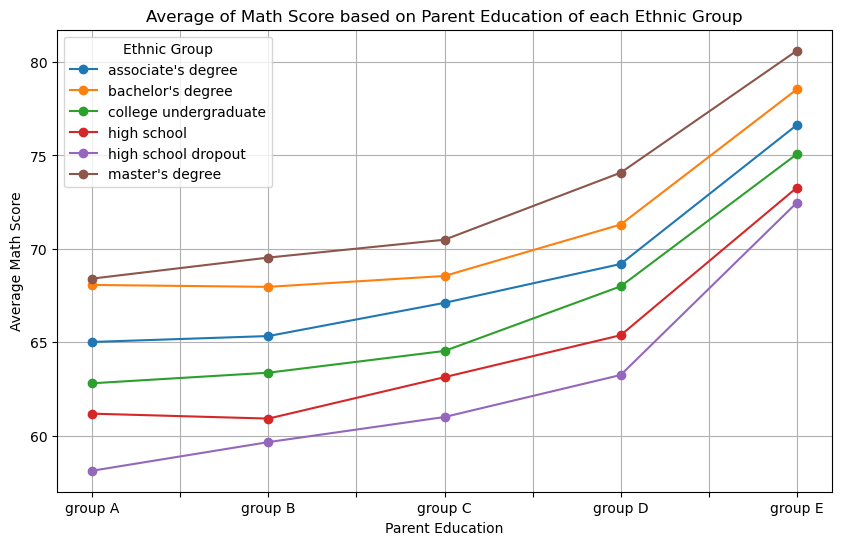

In [124]:
grouped_data = data.groupby(['EthnicGroup', 'ParentEduc'])['MathScore'].mean().unstack()

grouped_data.plot(kind='line', marker='o', figsize=(10, 6))

plt.title('Average of Math Score based on Parent Education of each Ethnic Group')
plt.xlabel('Parent Education')
plt.ylabel('Average Math Score')
plt.legend(title='Ethnic Group')
plt.grid(True)
plt.show()

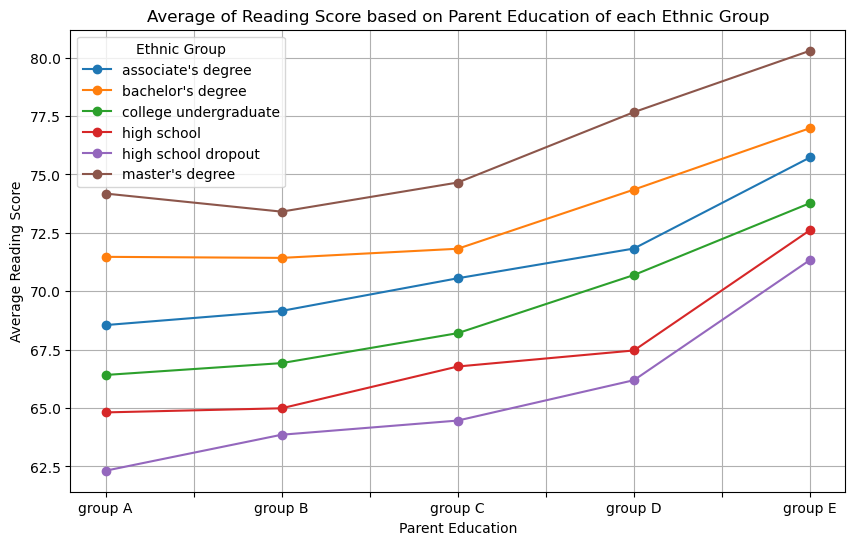

In [125]:
grouped_data = data.groupby(['EthnicGroup', 'ParentEduc'])['ReadingScore'].mean().unstack()

grouped_data.plot(kind='line', marker='o', figsize=(10, 6))

plt.title('Average of Reading Score based on Parent Education of each Ethnic Group')
plt.xlabel('Parent Education')
plt.ylabel('Average Reading Score')
plt.legend(title='Ethnic Group')
plt.grid(True)
plt.show()

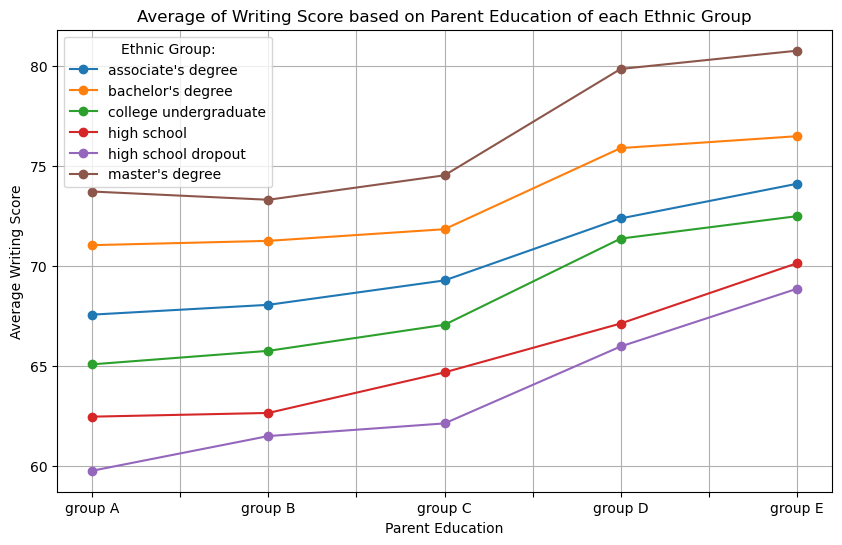

In [126]:
grouped_data = data.groupby(['EthnicGroup', 'ParentEduc'])['WritingScore'].mean().unstack()

grouped_data.plot(kind='line', marker='o', figsize=(10, 6))

plt.title('Average of Writing Score based on Parent Education of each Ethnic Group')
plt.xlabel('Parent Education')
plt.ylabel('Average Writing Score')
plt.legend(title='Ethnic Group:')
plt.grid(True)
plt.show()

(Intepretasi di bawah ini mencakup 3 graph line plot di atas)

Interpretasi Data secara vertikal:
- Pada line plot gabungan di atas terlihat bahwa kebanyakan bagian dari garis-garis tersebut tidak overlap, hal itu menunjukkan bahwa lulusan orang tua mempengaruhi nilai matematika, reading, dan writing anaknya. Anak dari orang tua dengan lulusan master's degree dari grup etnis apapun memiliki rata-rata nilai matematika, reading, dan writing yang paling tinggi. Sedangkan anak dari orang tua high school dropout memiliki kecenderungan nilai rata-rata matematika, reading, dan writing yang paling rendah.

Interpretasi Data secara Horizontal:
- Dapat dilihat pula ada tren kenaikan nilai rata rata matematika, reading, dan writing dari anak orang tua lulusan mana pun. Kenaikan ini dapat di lihat secara general ke area group E. Hal ini memberikan informasi bahwa anak dengan etnis group E cenderung memiliki nilai matematika, reading, dan writing yang paling tinggi dibandingkan nilai anak dengan etnis lainnya.

### E. Hubungan Nilai dengan Lunch Type

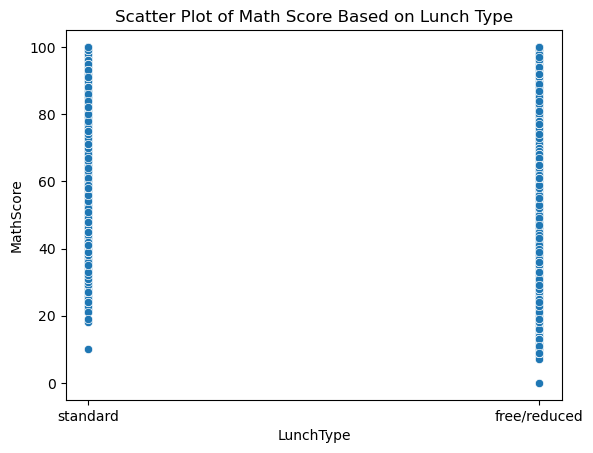

In [127]:
sns.scatterplot(x="LunchType", y="MathScore", data=data)
plt.title('Scatter Plot of Math Score Based on Lunch Type')
plt.show()

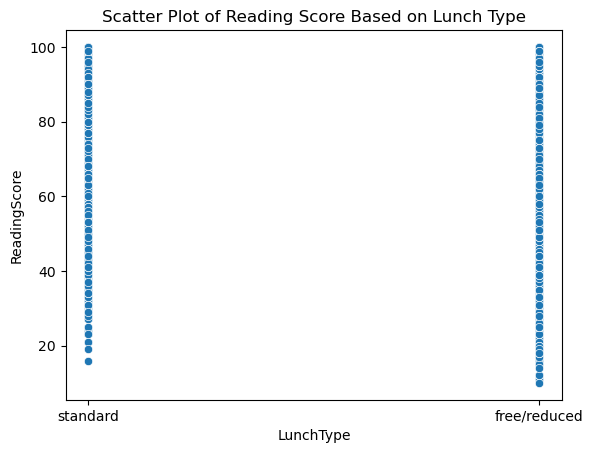

In [128]:
sns.scatterplot(x="LunchType", y="ReadingScore", data=data)
plt.title('Scatter Plot of Reading Score Based on Lunch Type')
plt.show()

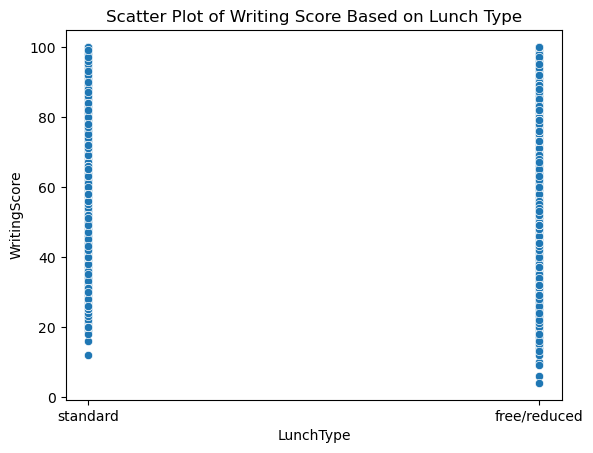

In [129]:
sns.scatterplot(x="LunchType", y="WritingScore", data=data)
plt.title('Scatter Plot of Writing Score Based on Lunch Type')
plt.show()

(Intepretasi di bawah ini mencakup 3 scatter plot di atas)

- Dari ketiga Scatter plot tersebut, ternyata lunch type dari anak dapat mempengaruhi nilai baik matematika, reading, ataupun writing. Hal ini terlihat dari penyebaran titik di area nilai minimum. Persebaran titik nilai anak dengan lunch type standard lebih berkonsentrasi di area atas. Di bagian di bawah nilai 20 bahkan hanya sedikit sekali titiknya. Sedangkan persebaran titik nilai anak dengan lunch type free/reduced lebih tersebar. Titik yang di bawah nilai 20 juga lebih banyak dari yang standard.

### F. Hubungan Nilai dengan Test Preparation

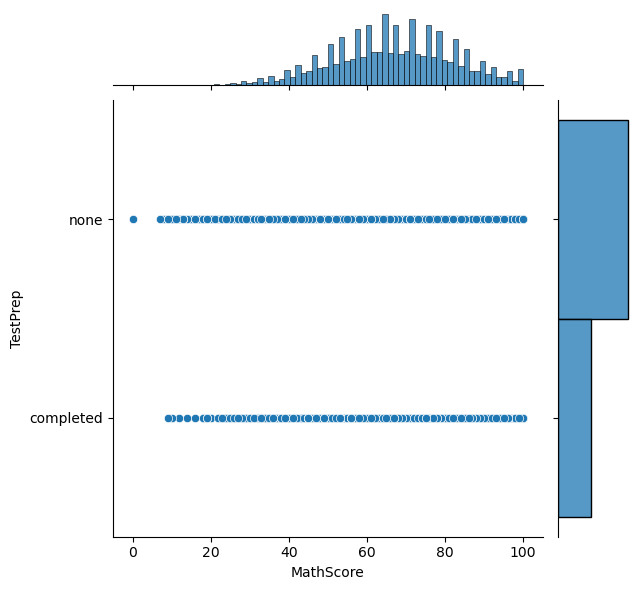

In [130]:
sns.jointplot(x="MathScore", y="TestPrep", kind="scatter", data=data)

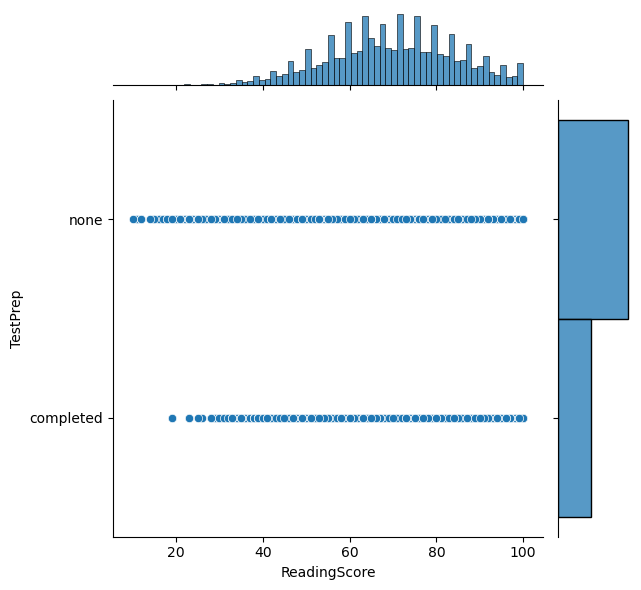

In [131]:
sns.jointplot(x="ReadingScore", y="TestPrep", kind="scatter", data=data)

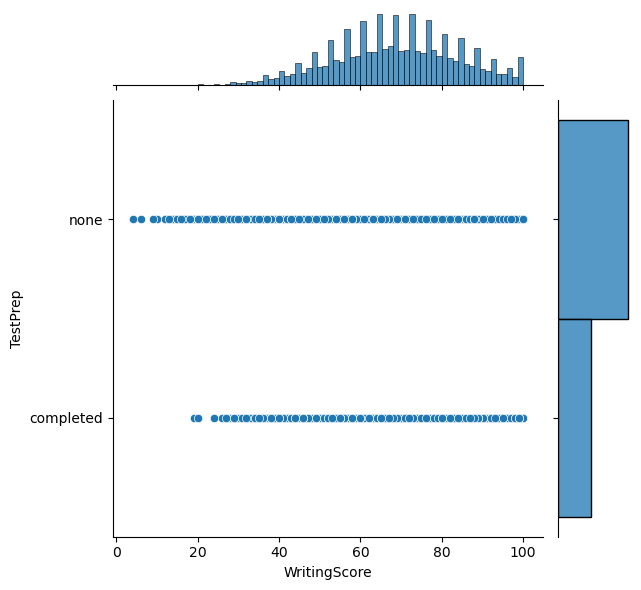

In [132]:
sns.jointplot(x="WritingScore", y="TestPrep", kind="scatter", data=data)

(Intepretasi di bawah ini mencakup 3 joint plot di atas)

- Dari ketiga bagian scatter dari joint plot tersebut, ternyata test preparation completion dari anak dapat mempengaruhi nilai baik matematika, reading, ataupun writing. Hal ini terlihat dari penyebaran titik di area nilai minimum. Persebaran titik nilai anak yang menyelesaikan test preparation lebih berkonsentrasi di area atas. Di bagian di bawah nilai 20 bahkan hanya sedikit sekali titiknya. Sedangkan persebaran titik nilai anak yang tidak mengikuti test preparation tersebut lebih tersebar. Titik yang di bawah nilai 20 juga lebih banyak.
- Terlihat pula dari ketiga bagian bar graph dari joint plot, bar yang none lebih tinggi daripada bar yang completed hal ini menunjukkan bahwa lebih banyak anak yang tidak mengikuti test prep dari pada yang mengikutinya.
- Bila kita bandingkan kembali scatter dari ketiga nilai yang anaknya menyelesaikan test prep, terlihat bahwa titik minimum nilai matematika lebih rendah di banding nilai writing dan reading. Hal ini menunjukkan bahwa test prep kemungkinan besar lebih membantu nilai reading dan writing dibandingkan nilai matematika.

### G. Hubungan Nilai dengan Weekly Study Hours

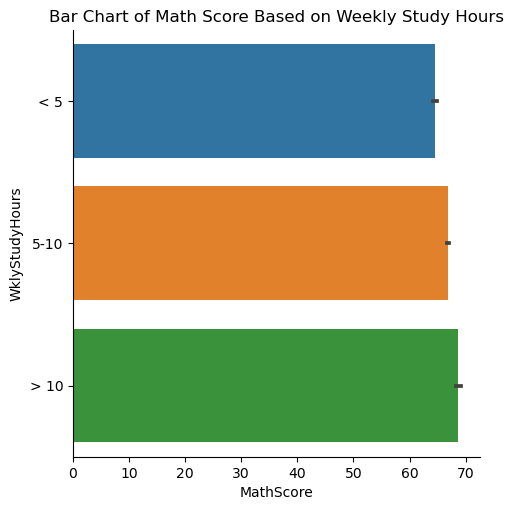

In [133]:
sns.catplot(data=data, x='MathScore', y='WklyStudyHours', kind="bar")
plt.title('Bar Chart of Math Score Based on Weekly Study Hours')
plt.show()

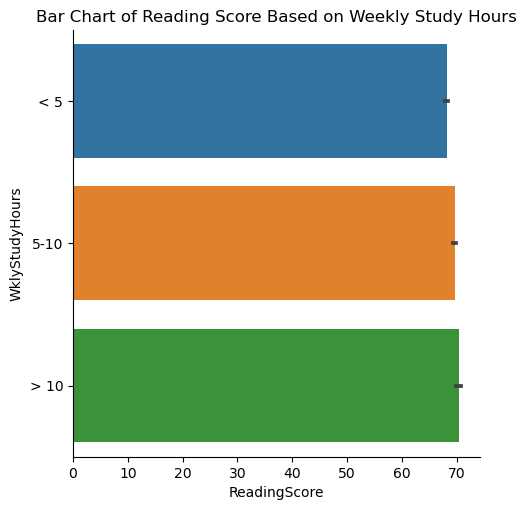

In [134]:
sns.catplot(data=data, x='ReadingScore', y='WklyStudyHours', kind="bar")
plt.title('Bar Chart of Reading Score Based on Weekly Study Hours')
plt.show()

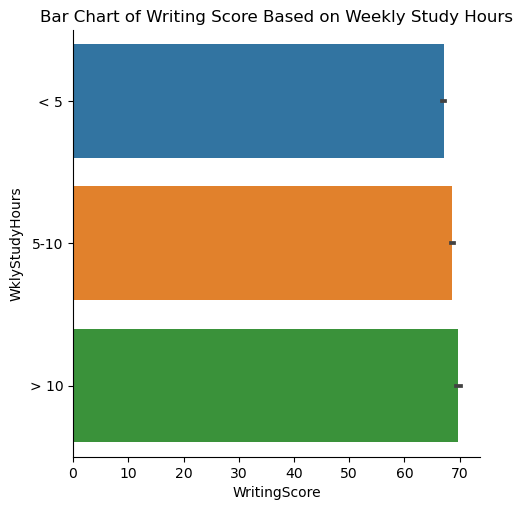

In [135]:
sns.catplot(data=data, x='WritingScore', y='WklyStudyHours', kind="bar")
plt.title('Bar Chart of Writing Score Based on Weekly Study Hours')
plt.show()

(Intepretasi di bawah ini mencakup 3 bar chart di atas)

- Ketiga bar chart di atas menunjukkan bahwa weakly study hours sedikit mempengaruhi nilai matematika, reading, mauppun writing murid. Bar-bar tersebut terlihat semakin panjang semakinm lama jam belajarnya. Misalnya, bar kurang dari 5 jam lebih pendek dari bar 5-10 jam. Sedangkan bar 5-10 jam lebih pendek dari bar lebih dari 10 jam. Teapi, pengaruhnya tidak terlalu besar, perbedaan panjangnya sangat kecil.

### H. Hubungan Nilai dengan Test Preparation and Weekly Study Hours

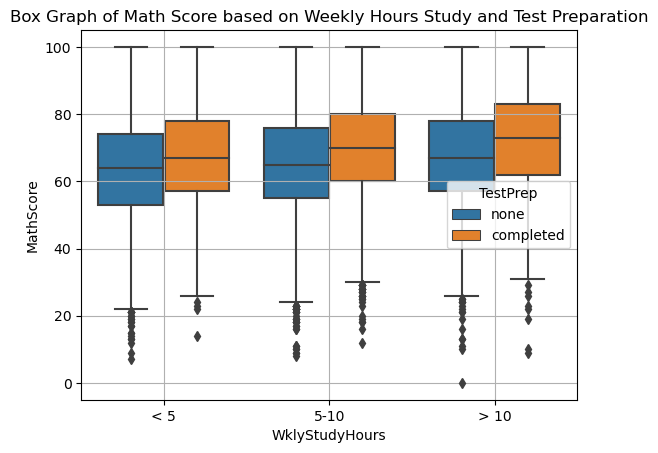

In [136]:
sns.boxplot(x="WklyStudyHours", y="MathScore", hue="TestPrep", data=data)
plt.grid(True)
plt.title("Box Graph of Math Score based on Weekly Hours Study and Test Preparation")
plt.show()

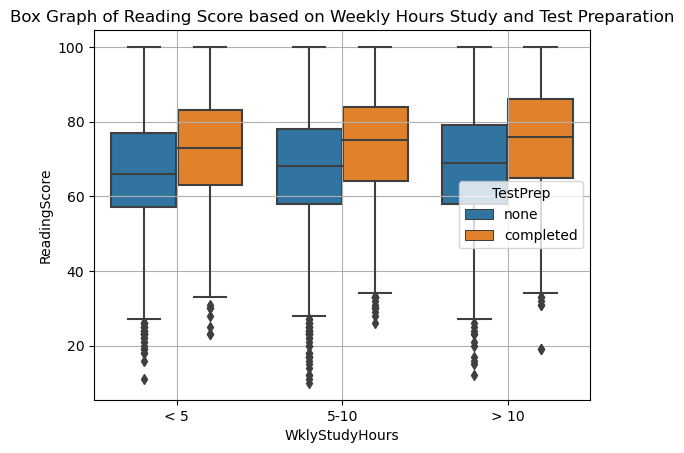

In [137]:
sns.boxplot(x="WklyStudyHours", y="ReadingScore", hue="TestPrep", data=data)
plt.grid(True)
plt.title("Box Graph of Reading Score based on Weekly Hours Study and Test Preparation")
plt.show()

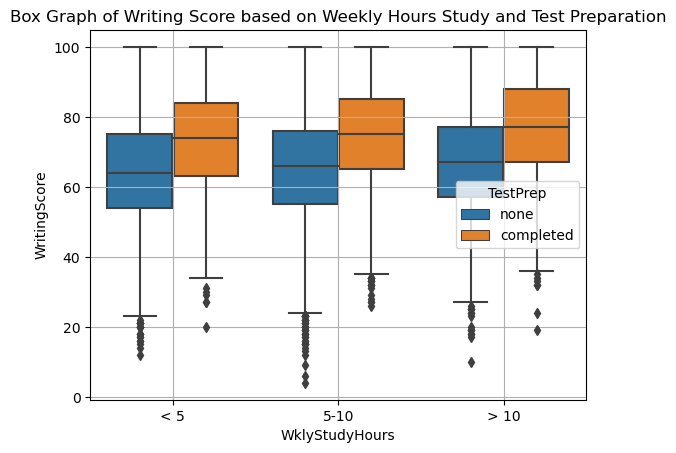

In [138]:
sns.boxplot(x="WklyStudyHours", y="WritingScore", hue="TestPrep", data=data)
plt.grid(True)
plt.title("Box Graph of Writing Score based on Weekly Hours Study and Test Preparation")
plt.show()

(interpretasi di bawah ini mencakup ketiga graph yang berisi box plot di atas)

- Nilai maksimal dari setiap kategori jam belajar maupun yang mengikuti dan tidak mengikuti class preparation sama-sama 100. Namun, terlihat pengaruh dari class preparation melalui nilai minimum. Terlihat bahwa untuk setiap box plot berwarna biru, nilai minimumnya lebih rendah dari nilai minimun box plot oren tepat di sebelahnya. Selain itu, median dan kuartil-kuartilnya box plot yang biru juga lebih rendah dari yang oren tepat di sebelahnya. Hal ini menunjukkan bahwa mengikuti test preparation memungkinkan nilai untuk menjadi lebih baik.
- Jam belajar juga dapat sedikit mempengaruhi nilai. Terlihat bahwa dari kotak biru 1 (di kirinya misalnya yang <5) ke kotak biru selanjutnya (di kanannya misalnya yang 5-10), terdapat peningkatan nilai median maupun kuartil atas dan bawah. Begitu pula untuk box plot-box plot yang oren, terlihat tren peningkatan semakin ke kanan. Ini berarti bahwa semakin lama jam belajarnya, semakin baik pula kemungkinan nilainya walaupun tidak terlalu signifikan.

### I. Hubungan Test Preparation dan Weekly Study Hours

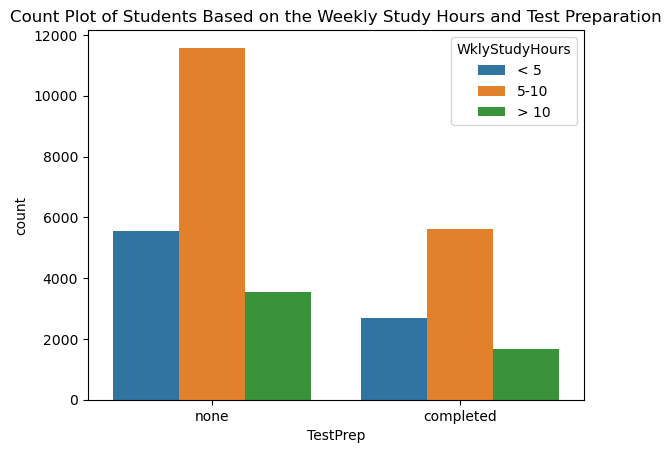

In [139]:
sns.countplot(x="TestPrep", hue="WklyStudyHours",data=data)
plt.title('Count Plot of Students Based on the Weekly Study Hours and Test Preparation')
plt.show()

Interpretasi data:
- Berdasarkan count plot di atas, terlihat bahwa lebih banyak murid yang tidak mengikuti test preparation.
- Untuk jumlah weekly study hours, ternyata mayoritas murid belajar 5-10 jam.

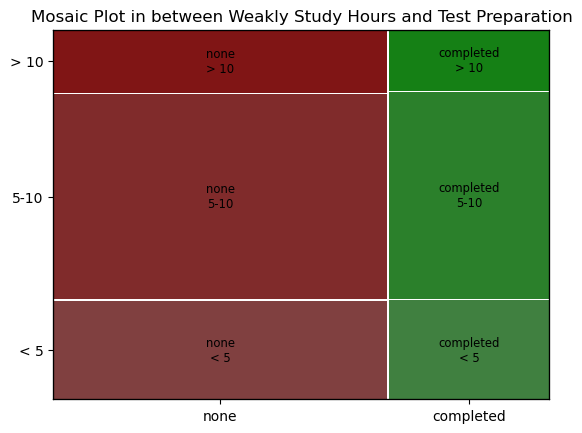

In [140]:
mosaic(data, ['TestPrep', 'WklyStudyHours'])
plt.title("Mosaic Plot in between Weakly Study Hours and Test Preparation")
plt.show()

Apakah anak yang mengikuti test preparation belajar lebih sedikit di luar jam sekolah?

Interpretasi data:
- Berdasarkan mosaic plot di atas, mengikuti atau tidak mengikuti test preparation tidak membuat murid belajar lebih banyak ataupun lebih sedikit di luar jam sekolah. Hal ini terlihat dari tinggi dari bagian merah dibandingkan dengan yang hijau tepat di sebelahnya. Bagian none < 5 misalnya tingginya mirip sekali dengan yang completed < 5. Begitupula tinggi non 5-10 mirip dengan tinggi completed 5-10.

### J. Hubungan Nilai dengan Parent Marital Status

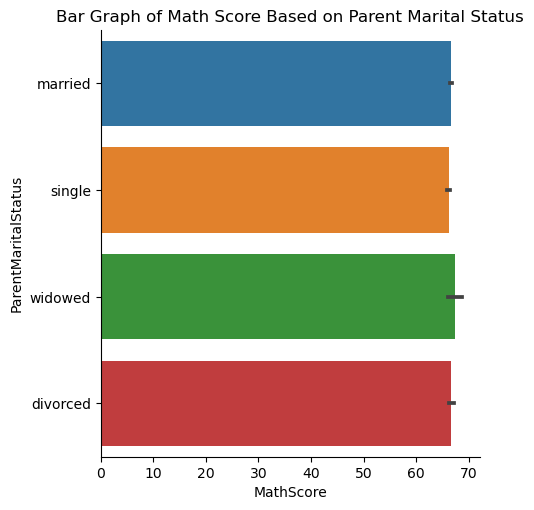

In [141]:
sns.catplot(data=data, x='MathScore', y='ParentMaritalStatus', kind="bar")
plt.title('Bar Graph of Math Score Based on Parent Marital Status')
plt.show()

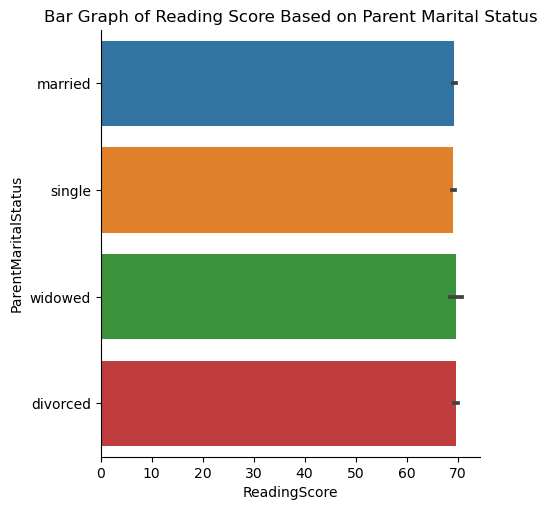

In [142]:
sns.catplot(data=data, x='ReadingScore', y='ParentMaritalStatus', kind="bar")
plt.title('Bar Graph of Reading Score Based on Parent Marital Status')
plt.show()

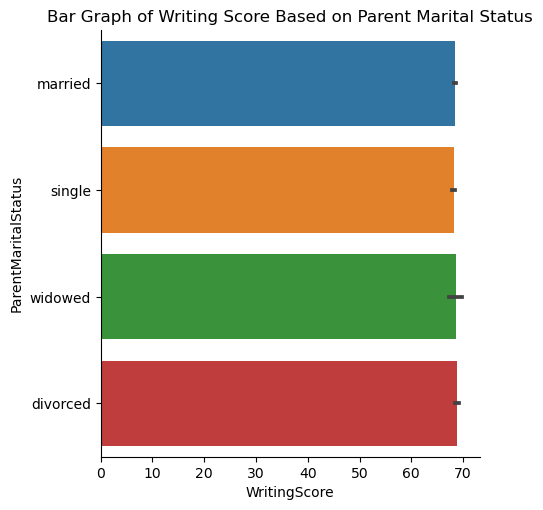

In [143]:
sns.catplot(data=data, x='WritingScore', y='ParentMaritalStatus', kind="bar")
plt.title('Bar Graph of Writing Score Based on Parent Marital Status')
plt.show()

(interpretasi di bawah ini mencakup ketiga Bar graph di atas)

- Terlihat bahwa untuk nilai matematika, reading, maupun writing, tidak ada perbedaan yang singnifikan tinggi bar antara setiap parent maritan statusnya. Hal ini menunjukkan bahwa parent marital status tidak begitu mempengaruhi nilai anaknya.

### K. Hubungan Nilai dengan Parent Marital Status dan Study Hours

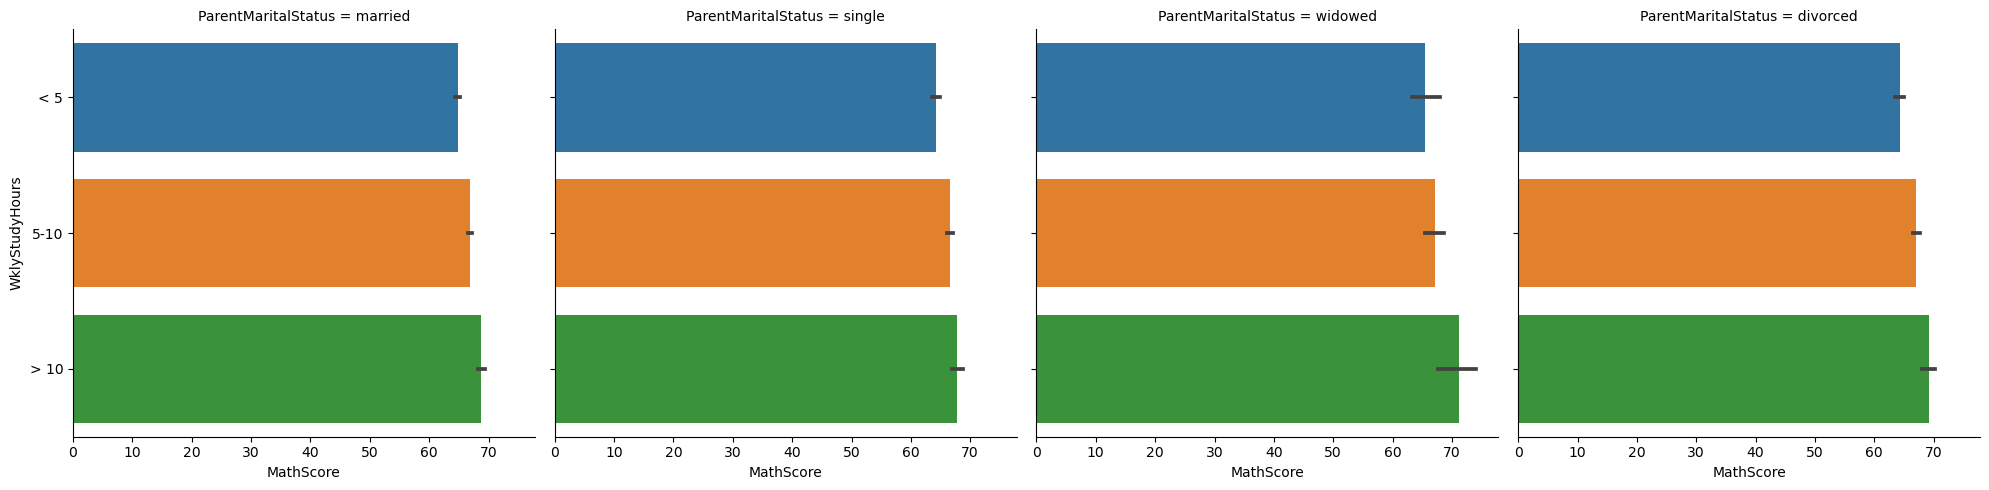

In [144]:
sns.catplot(data=data, x='MathScore', y='WklyStudyHours', col='ParentMaritalStatus', kind="bar")

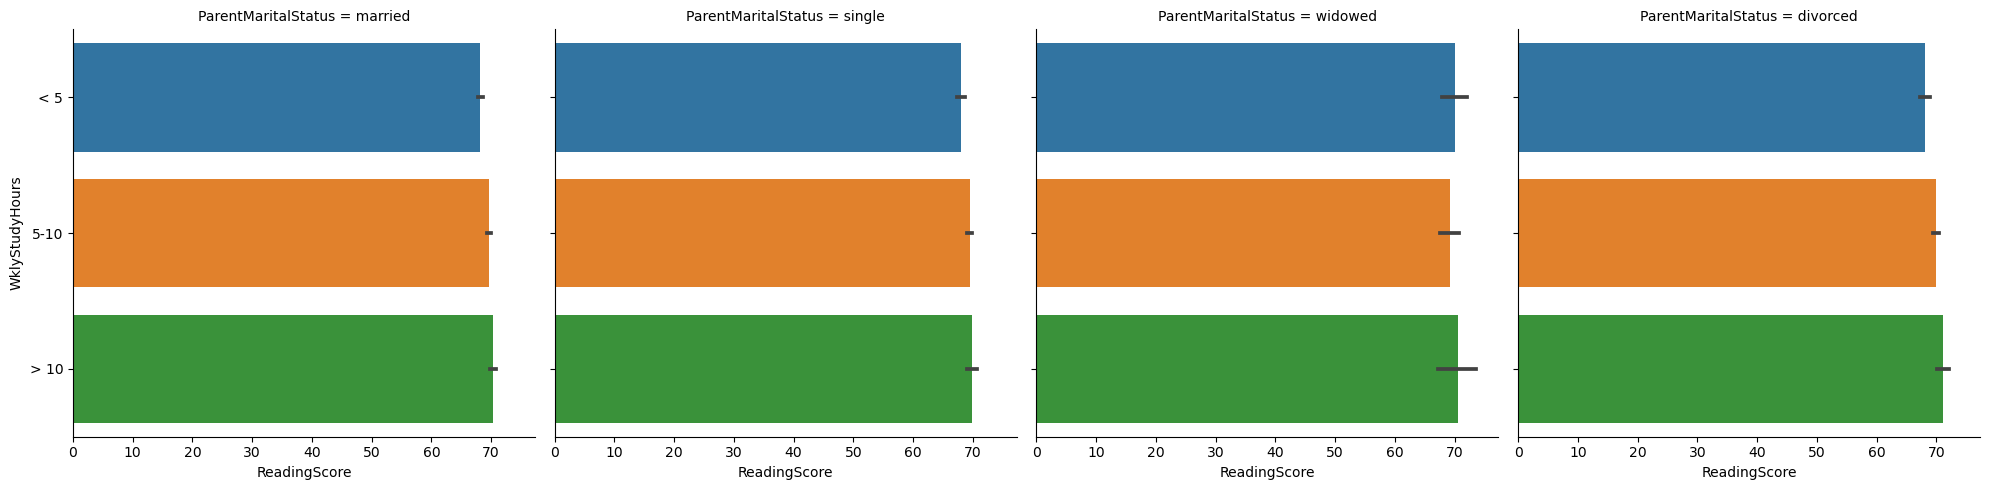

In [145]:
sns.catplot(data=data, x='ReadingScore', y='WklyStudyHours', col='ParentMaritalStatus', kind="bar")

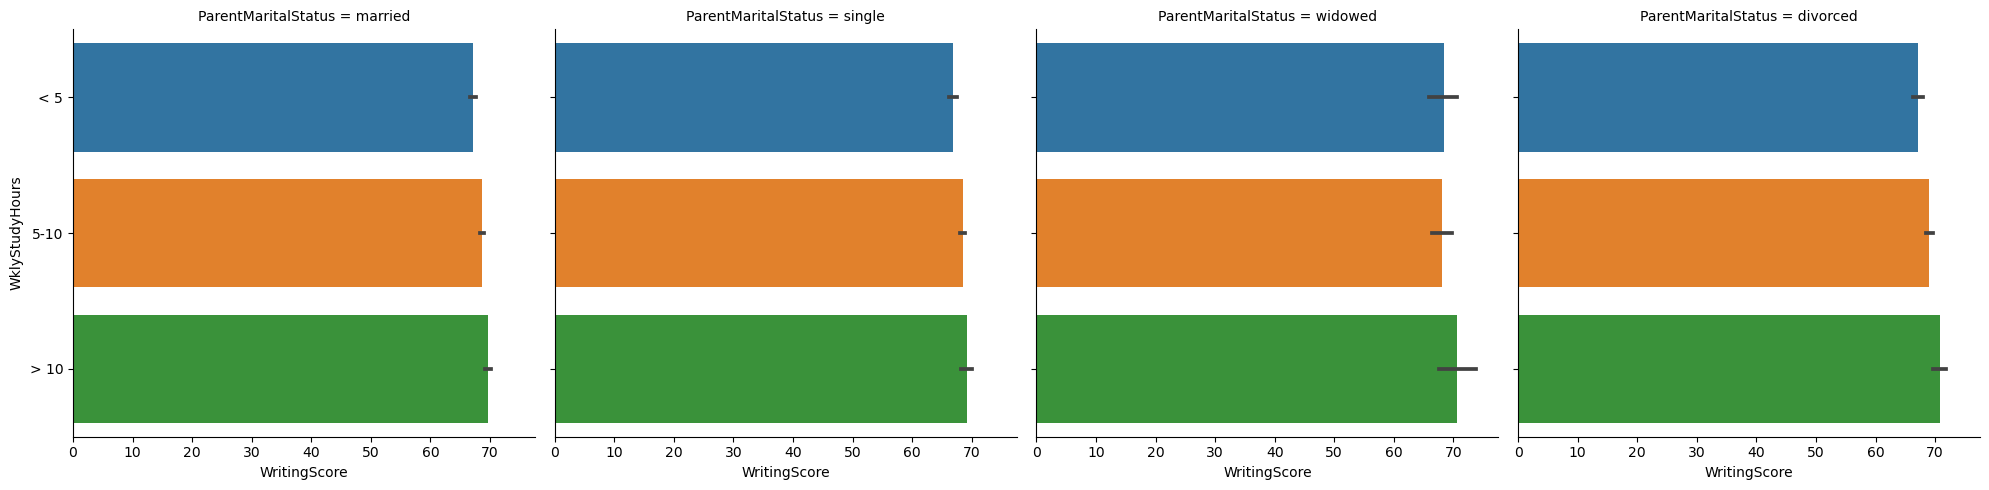

In [146]:
sns.catplot(data=data, x='WritingScore', y='WklyStudyHours', col='ParentMaritalStatus', kind="bar")

(interpretasi data di bawah ini mencakup ketiga gabungan bar-bar graph di atas)

- Bar-bar graph di atas hanya memperkuat pengetahuan bahwa parent marital status tidak ter lalu berpengaruh dengan nilai. Hal ini dapat diperhatikan dari perbandingan bar graph satu dengan yang di sebelahnya, tidak ada perubahan yang signifikan. 
- Kemudian, bar-bar di dalam bar graph di atas juga memperkuat pengetahuan bahwa jam belajar yang bertambah menghasilkan nilai ujian yang sedikit lebih baik. Bar-bar yang hijau selalu lebih panjang dari bar oren dan biru di atasnya walaupun tidak signifikan.

### L. Hubungan Nilai dengan IsFirstChild

In [147]:
data['IsFirstChild'].value_counts()

yes    19986
no     10655
Name: IsFirstChild, dtype: int64

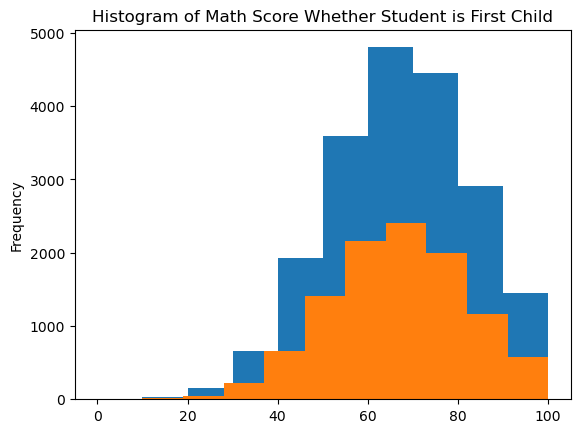

In [148]:
data[data['IsFirstChild']=='yes']['MathScore'].plot(kind='hist')
data[data['IsFirstChild']=='no']['MathScore'].plot(kind='hist')

plt.title('Histogram of Math Score Whether Student is First Child')
plt.show()

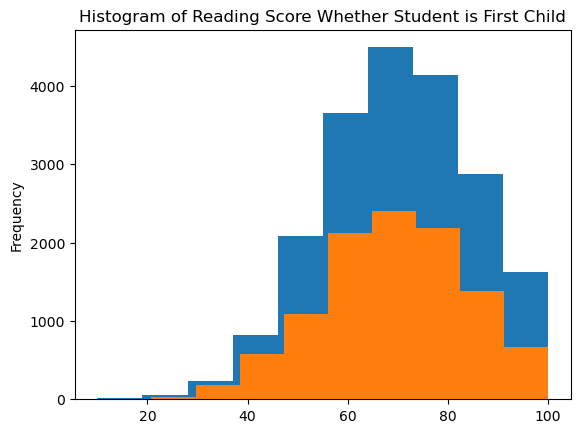

In [149]:
data[data['IsFirstChild']=='yes']['ReadingScore'].plot(kind='hist')
data[data['IsFirstChild']=='no']['ReadingScore'].plot(kind='hist')

plt.title('Histogram of Reading Score Whether Student is First Child')
plt.show()

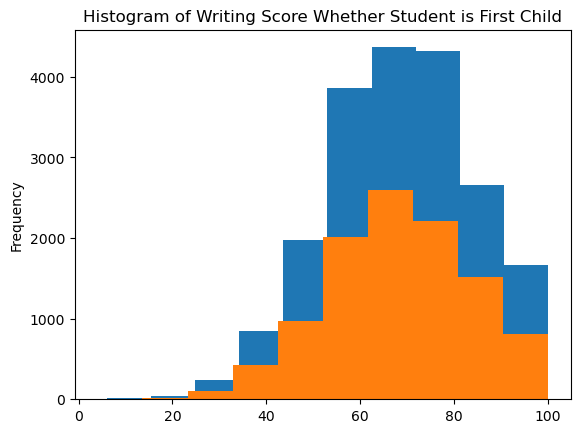

In [150]:
data[data['IsFirstChild']=='yes']['WritingScore'].plot(kind='hist')
data[data['IsFirstChild']=='no']['WritingScore'].plot(kind='hist')

plt.title('Histogram of Writing Score Whether Student is First Child')
plt.show()

(interpretasi data di bawah ini mencakup ketiga gabungan histogram di atas)

- Terlihat jelas bahwa histogram yang berwarna biru selalu lebih tinggi dari yang warna oren. Ini menunjukkan bahwa anak yang menjadi anak pertama selalu lebih banyak dari yang bukan anak pertama.
- Untuk nilainya tidak terlalu terlihat di graph-graph di atas pengaruh menjadi anak pertama atau tidaknya. Di bawah akan kami coba menggunakan graph jenis lain.

### M.Hubungan Nilai dengan Anak Pertama dari n-Bersaudara

In [151]:
data['NrSiblings'].value_counts()

2.0    8362
1.0    8217
3.0    6123
0.0    3085
4.0    2941
5.0    1320
6.0     302
7.0     291
Name: NrSiblings, dtype: int64

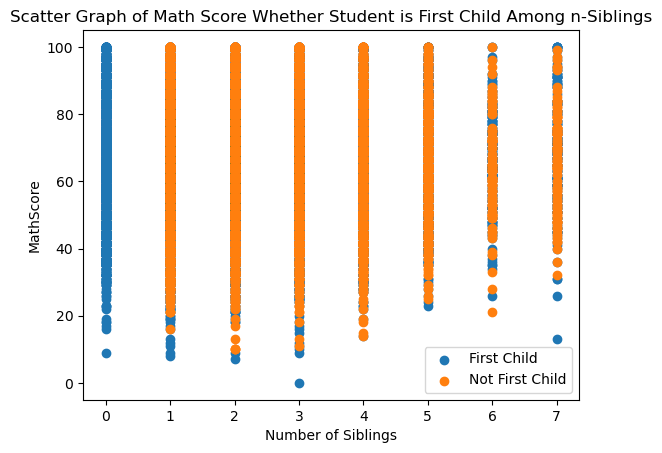

In [152]:
first_child = data[data['IsFirstChild'] == 'yes']
not_first_child = data[data['IsFirstChild'] == 'no']

plt.scatter(x= first_child['NrSiblings'], y= first_child['MathScore'], label='First Child')
plt.scatter(x= not_first_child['NrSiblings'], y= not_first_child['MathScore'], label='Not First Child')

plt.title('Scatter Graph of Math Score Whether Student is First Child Among n-Siblings')
plt.xlabel('Number of Siblings')
plt.ylabel('MathScore')
plt.legend()
plt.show()

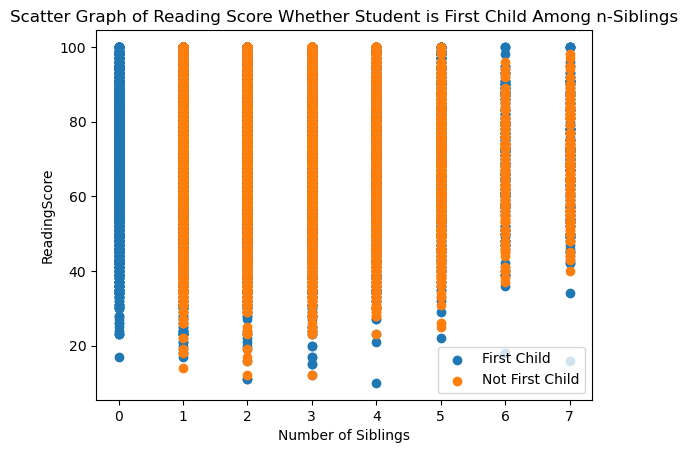

In [153]:
first_child = data[data['IsFirstChild'] == 'yes']
not_first_child = data[data['IsFirstChild'] == 'no']

plt.scatter(x= first_child['NrSiblings'], y= first_child['ReadingScore'], label='First Child')
plt.scatter(x= not_first_child['NrSiblings'], y= not_first_child['ReadingScore'], label='Not First Child')

plt.title('Scatter Graph of Reading Score Whether Student is First Child Among n-Siblings')
plt.xlabel('Number of Siblings')
plt.ylabel('ReadingScore')
plt.legend()
plt.show()

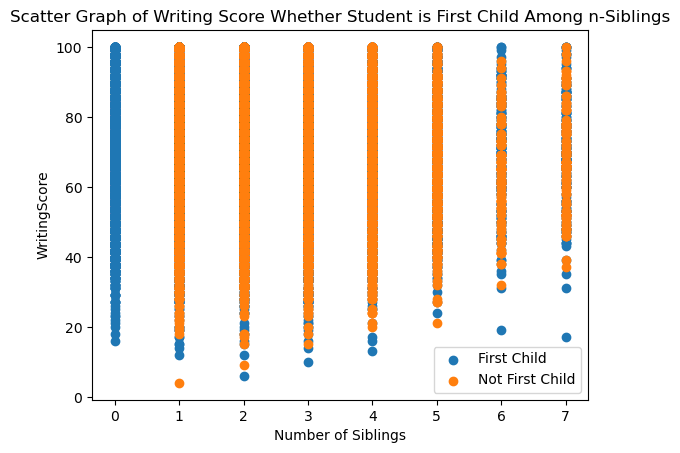

In [154]:
first_child = data[data['IsFirstChild'] == 'yes']
not_first_child = data[data['IsFirstChild'] == 'no']

plt.scatter(x= first_child['NrSiblings'], y= first_child['WritingScore'], label='First Child')
plt.scatter(x= not_first_child['NrSiblings'], y= not_first_child['WritingScore'], label='Not First Child')

plt.title('Scatter Graph of Writing Score Whether Student is First Child Among n-Siblings')
plt.xlabel('Number of Siblings')
plt.ylabel('WritingScore')
plt.legend()
plt.show()

(interpretasi data di bawah ini mencakup ketiga scatter plot di atas)

- Bila kita bandingkan nilai matematika, reading, ataupun writing berdasarkan berbagai jumlah siblings, kita mendapati bahwa murid yang jumlah saudaranya sekitar 5, 6, atau 7, tidak banyak yang nilainya rendah. Namun, kepadatan titik-titiknya juga semakin berkurang di area nilai tinggi. Tetapi, terlihat persebarannya tidak mengikuti tren tertentu jadi dapat dikatakan behwa jumlah saudara tidak begitu mempengaruhi nilai. Hal ini juga dibuktikan dengan perbandingan mean di bawah ini. Nilai-nilai meannya tidak terlihat terpengaruh oleh jumlah saudara.

In [155]:
groupdata = data.groupby(by='NrSiblings')
groupdata['MathScore'].mean()

NrSiblings
0.0    66.819449
1.0    66.473896
2.0    66.512557
3.0    66.719092
4.0    66.245495
5.0    66.630303
6.0    65.917219
7.0    67.615120
Name: MathScore, dtype: float64

In [156]:
groupdata['ReadingScore'].mean()

NrSiblings
0.0    69.547812
1.0    69.259097
2.0    69.425257
3.0    69.488159
4.0    69.144169
5.0    69.453788
6.0    68.801325
7.0    69.828179
Name: ReadingScore, dtype: float64

In [157]:
groupdata['WritingScore'].mean()

NrSiblings
0.0    68.746515
1.0    68.245345
2.0    68.441402
3.0    68.650498
4.0    68.073444
5.0    68.282576
6.0    67.860927
7.0    68.986254
Name: WritingScore, dtype: float64

Lanjutan interpretasi:
- Lokasi titik-titik yang berwarna oren juga mirip sekali dengan lokasi titik-titik biru di belakangnya. Hal ini berarti nilai matematika, reading, maupun writing tidak begitu dipengaruhi oleh status murid sebagai anak pertama ataupun bukan. Pernyataan ini diperkuat oleh data-data mean di bawah ini:

In [158]:
groupdata2 = data.groupby(by='IsFirstChild')
groupdata2['MathScore'].mean()

IsFirstChild
no     66.246832
yes    66.724507
Name: MathScore, dtype: float64

In [159]:
groupdata2['ReadingScore'].mean()

IsFirstChild
no     69.132614
yes    69.508106
Name: ReadingScore, dtype: float64

In [160]:
groupdata2['WritingScore'].mean()

IsFirstChild
no     68.210887
yes    68.529371
Name: WritingScore, dtype: float64

--------------------------------------------------------------------------------------------------------------------------------

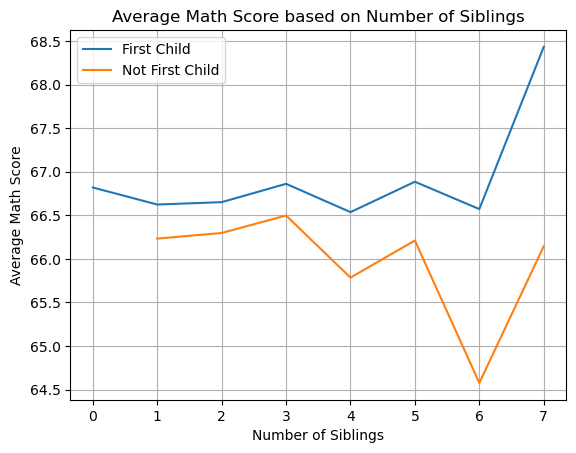

In [161]:
first_child = data[data['IsFirstChild'] == 'yes']
not_first_child = data[data['IsFirstChild'] == 'no']

avg_math_first_child = first_child.groupby('NrSiblings')['MathScore'].mean()
avg_math_not_first_child = not_first_child.groupby('NrSiblings')['MathScore'].mean()

plt.plot(avg_math_first_child.index, avg_math_first_child.values, label='First Child')
plt.plot(avg_math_not_first_child.index, avg_math_not_first_child.values, label='Not First Child')

plt.xlabel('Number of Siblings')
plt.ylabel('Average Math Score')
plt.title('Average Math Score based on Number of Siblings')
plt.legend()
plt.grid(True)
plt.show()

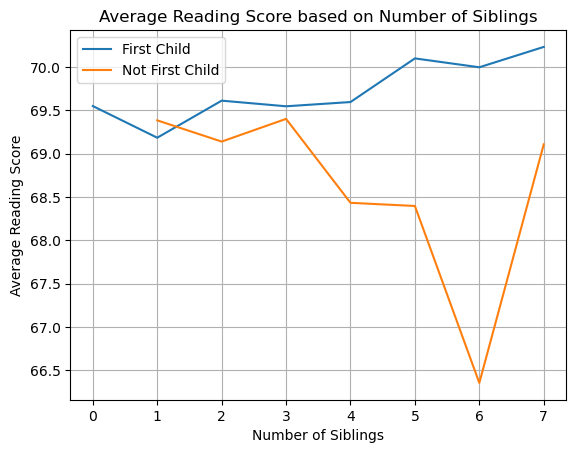

In [162]:
first_child = data[data['IsFirstChild'] == 'yes']
not_first_child = data[data['IsFirstChild'] == 'no']

avg_reading_first_child = first_child.groupby('NrSiblings')['ReadingScore'].mean()
avg_reading_not_first_child = not_first_child.groupby('NrSiblings')['ReadingScore'].mean()

plt.plot(avg_reading_first_child.index, avg_reading_first_child.values, label='First Child')
plt.plot(avg_reading_not_first_child.index, avg_reading_not_first_child.values, label='Not First Child')

plt.xlabel('Number of Siblings')
plt.ylabel('Average Reading Score')
plt.title('Average Reading Score based on Number of Siblings')
plt.legend()
plt.grid(True)
plt.show()

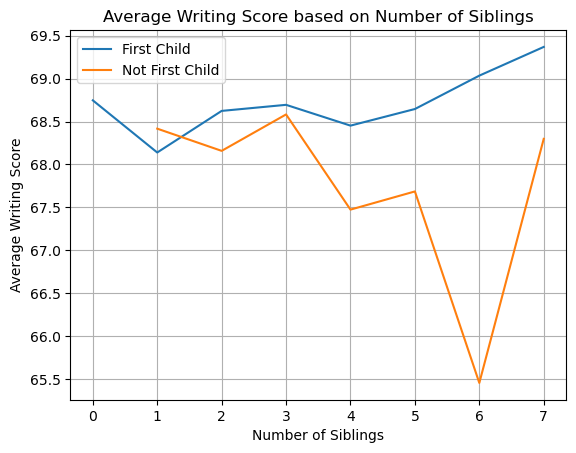

In [163]:
first_child = data[data['IsFirstChild'] == 'yes']
not_first_child = data[data['IsFirstChild'] == 'no']

avg_writing_first_child = first_child.groupby('NrSiblings')['WritingScore'].mean()
avg_writing_not_first_child = not_first_child.groupby('NrSiblings')['WritingScore'].mean()

plt.plot(avg_writing_first_child.index, avg_writing_first_child.values, label='First Child')
plt.plot(avg_writing_not_first_child.index, avg_writing_not_first_child.values, label='Not First Child')

plt.xlabel('Number of Siblings')
plt.ylabel('Average Writing Score')
plt.title('Average Writing Score based on Number of Siblings')
plt.legend()
plt.grid(True)
plt.show()

(interpretasi data di bawah ini mencakup ketiga line graph di atas)

- Sama seperti scatter plot sebelumnya, line chart ini juga menggambarkan bahwa number of siblings ataupun status is first child tidak mempengaruhi rata-rata nilai baik matematika, reading, ataupun writing. Walaupun graph-graph di atas memperlihatkan bahwa garis yang berwarna biru selalu di atas garis berwarna oren, kita perhatikan y-axis yang menampilkan nilai rata-rata. Perbedaan setiap bagian hanya hitungan 0.5. Semua nilai rata-ratanya dalam kisaran 65.5 hingga 69.5. Ini adalah lingkup yang kecil walaupun di gambar terlihat ada perbedaan besar.

### N. Hubungan Nilai dengan Weekly Study Hours dan Practice Sport

Text(0.5, 1.0, 'Line Graph of Math Score Based on Weekly Study Hours and Practice Sport')

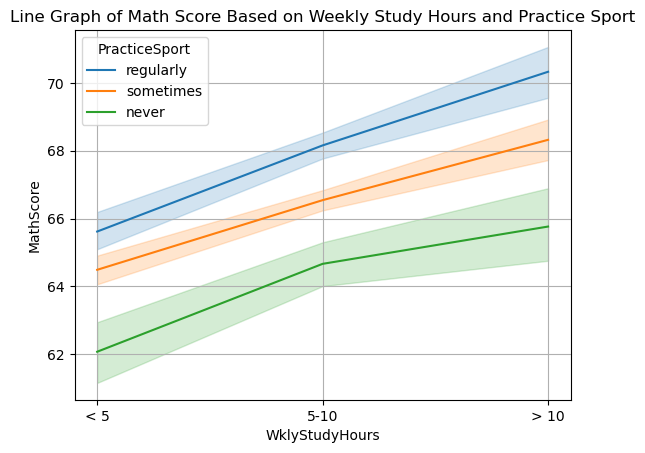

In [164]:
sns.lineplot(x='WklyStudyHours', y='MathScore', hue='PracticeSport', data=data)
plt.grid(True)
plt.title('Line Graph of Math Score Based on Weekly Study Hours and Practice Sport')

Text(0.5, 1.0, 'Line Graph of Reading Score Based on Weekly Study Hours and Practice Sport')

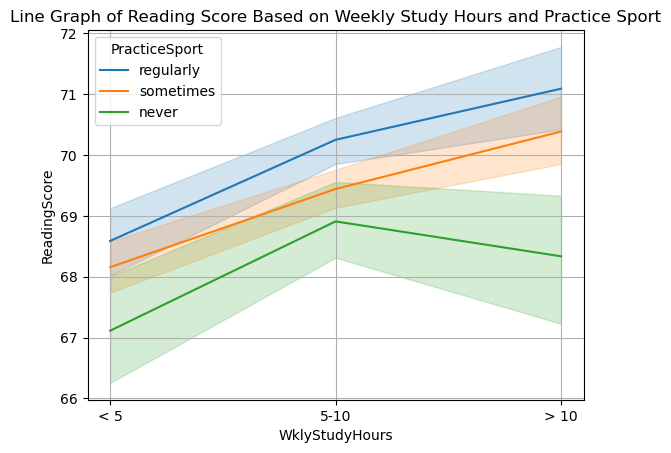

In [165]:
sns.lineplot(x='WklyStudyHours', y='ReadingScore', hue='PracticeSport', data=data)
plt.grid(True)
plt.title('Line Graph of Reading Score Based on Weekly Study Hours and Practice Sport')

Text(0.5, 1.0, 'Line Graph of Writing Score Based on Weekly Study Hours and Practice Sport')

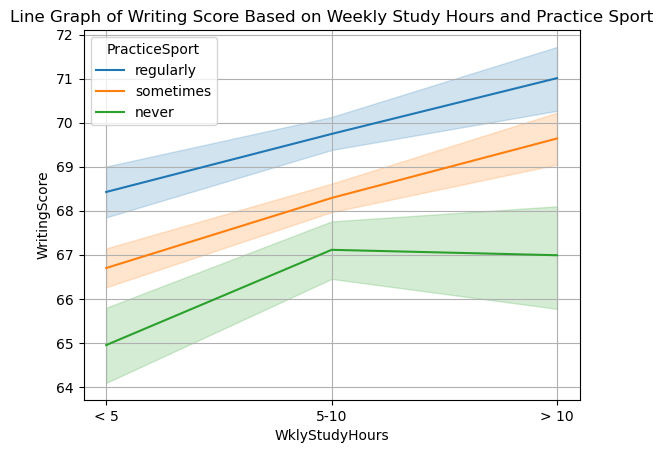

In [166]:
sns.lineplot(x='WklyStudyHours', y='WritingScore', hue='PracticeSport', data=data)
plt.grid(True)
plt.title('Line Graph of Writing Score Based on Weekly Study Hours and Practice Sport')

(interpretasi data di bawah ini mencakup ketiga line graph di atas)

- Terlihat bahwa garis yang berwarna biru selalu di atas garis oren. Garis oren juga selalu di atas garis hijau. Hal ini menunjukkan bahwa semakin sering murid latihan sport, semakin tinggi juga nilai rata-ratanya. Tetapi, kita perhatikan lagi kenaikannya. Terlihat bahwa kenaikan nilai rata-ratanya cukup kecil. Misalnya di graph writing score, perbedaaan rata-rata nilai anak yang belajar <5 jam seminggu dari yang tidak pernah latihan olahraga ke yang selalu latihan, perbedaanya hanya 69-65, yaitu 4 nilai. Jadi, bisa dibilang intensitas latihan olahraga berpengaruh tetapi tidak terlalu besar dampaknya.

### O. Hubungan Nilai dengan Transport Means

<Axes: ylabel='TransportMeans'>

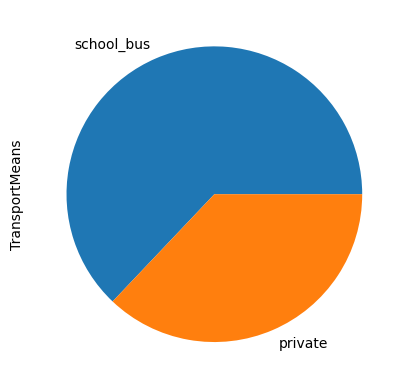

In [167]:
data['TransportMeans'].value_counts().plot(kind = 'pie')

Interpretasi data:
- Pie chart di atas menunjukkan bahwa lebih banyak bagiannya yang berwarna biru. Artinya, lebih banyak murid yang menggunakan school bus untuk pergi ke sekolah dibandingkan menmggunakan transportasi pribadi.

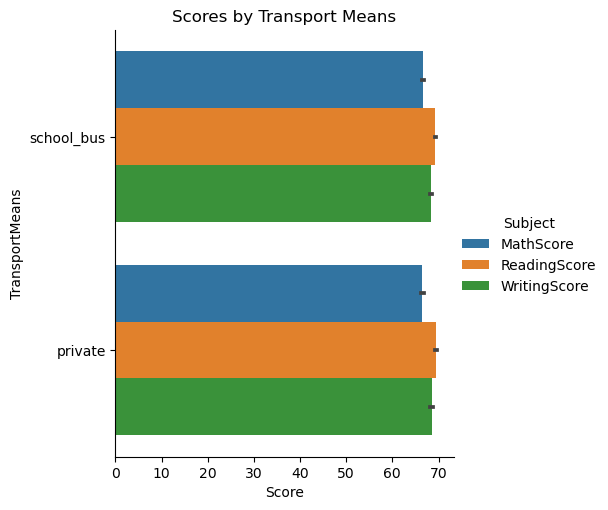

In [168]:
merged_data = pd.melt(data, id_vars=['TransportMeans'], value_vars=['MathScore', 'ReadingScore', 'WritingScore'], var_name='Subject', value_name='Score')
sns.catplot(data=merged_data, x='Score', y='TransportMeans', kind="bar", hue='Subject')
plt.title('Scores by Transport Means')
plt.show()

Interpretasi data:
- Terlihat bahwa saat kita membandingkan bar warna biru di atas dengan bawah, maupun bar oren atas dan bawah, atau bar hijau atas dan bawah, perbedaan panjang barnya sangat kecil. Bahkan hampir tidak terlihat berbeda. Ini berarti transport means kurang dapat mempengaruhi nilai jenis apapun.

# Conclusion:

   Berdasarkan deskripsi statistik, visualisasi, dan interpretasi di file ini, dapat disumpulkan bahwa faktor yang mempengaruhi nilai matematika secara berurutan dari yang paling berpengaruh adalah ethnic group, lunch type, parent education, gender, dan test preparation. Untuk reading, faktor yang paling berpengaruh adalah parent education, ethnic group, lunch type, test preparation, dan gender. Kemudian, untuk writing, faktor-faktornya adalah parent education, gender, lunch type, test preparation, dan ethnic group.